# Nation clustering with socioeconomic indicators

**DS203 code submission - reproducible analysis of 2022 WDI indicators.**

Research question: do economies form interpretable socioeconomic groups, how do those groups compare with external income/region labels, and how do K-means and hierarchical clustering differ?

The main analysis uses all 11 specified numerical indicators. World Bank income group, region and lending type are retained exclusively for interpretation. **2022 indicator values are compared with the metadata snapshot dated 23 November 2026; this is not a historical 2022 classification exercise.**

This notebook extends the supplied teammate baseline. The original raw-GDP result is preserved as a reproducible sensitivity analysis. Only K-means, PCA and the professor-permitted hierarchical method are used. ARI and NMI are descriptive comparison metrics, not additional clustering models.

## How to run

Clone the repository, install the dependencies in `requirements.txt`, and open this notebook from the repository root. Choose **Restart Kernel and Run All**. The analysis runs offline using the frozen World Bank data in this repository. `analysis.py` contains the full editable implementation. Each stage below calls a documented function; exported PNG/PDF charts and CSV tables are recreated.

The report and video accompany the separate course submission.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / 'analysis.py').is_file():
    raise FileNotFoundError('Open the notebook from the extracted Codebase folder.')
sys.path.insert(0, str(ROOT))
import analysis as project

def show_figures(*names):
    for name in names:
        display(Image(filename=str(ROOT / 'outputs/figures' / f'{name}.png')))

display(Markdown('### Fixed configuration'))
display(project.CONFIG)


### Fixed configuration

{'year': 2022,
 'missing_fraction_max': 0.5,
 'log_gdp': True,
 'pca_variance_target': 0.8,
 'k_values': [2, 3, 4, 5, 6, 7, 8],
 'random_state': 42,
 'n_init': 50,
 'hierarchical_linkage': 'ward',
 'candidate_years': [2021, 2022, 2023, 2024],
 'year_min_retained_fraction': 0.9,
 'year_min_complete_fraction': 0.5}

## 1. Source data, country selection and missingness

Source: official World Bank WDI numerical indicators and official World Bank Country API metadata. `data/provenance.json` records URLs, dates, sizes and SHA-256 hashes. Candidate years 2021-2024 are compared using one WDI API release and the same 217-economy official roster. Selection policy: choose the latest year retaining at least 90% of that roster with at least six observed indicators, and with at least half the roster fully observed. This chooses 2022 (205 retained, 110 complete cases). The 2021 data has better coverage, while 2023 has only 107 complete cases and narrowly misses the chosen 50% floor; the policy is a transparent design choice, not a statistical optimum.

The bulk CSV is replaced by a small equivalent 11-indicator snapshot. Aggregate entities are removed using metadata, not guessed from names. Country-code merges are validated. Missingness is reported before any deletion or imputation. Economies with more than half the 11 indicators missing are excluded; the remaining missing values are median-imputed globally, without reference labels. A stricter threshold and complete cases are checked later.

### 1.1 Candidate-year policy and complete entity reconciliation

The full 266-entity reconciliation distinguishes 44 coded aggregates, five uncoded income-classification aggregates (including Not classified), 217 eligible economies, and the separate 12 missingness exclusions. Unknown nonblank codes cause an explicit review error. The final 205-economy roster is exported with country codes.

Evidence links: [all 266 entities](outputs/tables/28_entity_reconciliation.csv), [12 missingness exclusions](outputs/tables/02_excluded_economies.csv), [final 205-economy roster and assignments](data/processed/country_cluster_assignments.csv).


In [2]:
state = project.load_data()
display(state['countries'].head())
display(state['coverage'].loc[~state['coverage'].retained])
display(state['countries'][project.FEATURES].isna().sum().sort_values(ascending=False))

project.candidate_years(state)
display(state['year_comparison'].round(3))
display(pd.read_csv(ROOT / 'outputs/tables/29_country_reconciliation_flow.csv'))

display(pd.DataFrame({'feature': list(project.INDICATORS), 'WDI_ID': list(project.INDICATORS.values())}))


DATA AUDIT: {'wdi_entities': 266, 'metadata_economies': 217, 'matched_economies': 217, 'excluded': 12, 'retained': 205, 'complete_cases': 110, 'coded_aggregates': 44, 'uncoded_income_aggregates': 5}
Income/region labels describe the metadata snapshot, not historical indicator-year classifications.


,Country Name,Country Code,Electricity_Access,Inflation,Internet_Users,Capital_Formation,Trade,GDP_Growth,GDP_PC,Secondary_Enrollment,Unemployment,Life_Expectancy,Urban_Population,Region,IncomeGroup,LendingType
0,Afghanistan,AFG,85.3,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100,65.617,25.393925,"Middle East, North Africa, Afghanistan & Pakistan",Low income,IDA
1,Albania,ALB,100.0,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785,78.769,57.864348,Europe & Central Asia,Upper middle income,IBRD
2,Algeria,DZA,100.0,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382,76.129,74.179586,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,IBRD
3,American Samoa,ASM,NaN,NaN,NaN,NaN,124.684271,1.735016,18017.458938,NaN,NaN,72.752,81.794798,East Asia & Pacific,High income,Not classified
4,Andorra,AND,100.0,NaN,94.051697,NaN,NaN,9.564612,42414.059011,98.509872,NaN,84.016,88.754877,Europe & Central Asia,High income,Not classified


,Country Code,Country Name,IncomeGroup,Region,LendingType,missing_indicators,missing_fraction,retained,reason
3,ASM,American Samoa,High income,East Asia & Pacific,Not classified,6,0.545455,False,Missing fraction exceeds 50%
27,VGB,British Virgin Islands,High income,Latin America & Caribbean,Not classified,7,0.636364,False,Missing fraction exceeds 50%
50,CUW,Curacao,High income,Latin America & Caribbean,Not classified,6,0.545455,False,Missing fraction exceeds 50%
61,ERI,Eritrea,Low income,Sub-Saharan Africa,IDA,6,0.545455,False,Missing fraction exceeds 50%
75,GIB,Gibraltar,High income,Europe & Central Asia,Not classified,7,0.636364,False,Missing fraction exceeds 50%
94,IMN,Isle of Man,High income,Europe & Central Asia,Not classified,6,0.545455,False,Missing fraction exceeds 50%
103,PRK,"Korea, Dem. People's Rep.",Low income,East Asia & Pacific,Not classified,7,0.636364,False,Missing fraction exceeds 50%
114,LIE,Liechtenstein,High income,Europe & Central Asia,Not classified,6,0.545455,False,Missing fraction exceeds 50%
172,SXM,Sint Maarten (Dutch part),High income,Latin America & Caribbean,Not classified,6,0.545455,False,Missing fraction exceeds 50%
178,SSD,South Sudan,Low income,Sub-Saharan Africa,IDA,6,0.545455,False,Missing fraction exceeds 50%


Secondary_Enrollment    77
Capital_Formation       42
Inflation               38
Internet_Users          35
Trade                   34
Unemployment            31
GDP_PC                   8
GDP_Growth               8
Electricity_Access       2
Life_Expectancy          0
Urban_Population         0
dtype: int64

Coverage policy: latest candidate retaining at least 90% of the fixed roster with at least 50% fully observed.
 year  eligible_roster  complete_cases  at_least_six_observed  retained_at_main_cutoff  missing_cells_percent worst_covered_indicator  worst_indicator_missing_percent  meets_coverage_policy  selected
 2021              217             116                    206                      206              11.143695    Secondary_Enrollment                        31.797235                   True     False
 2022              217             110                    205                      205              11.520737    Secondary_Enrollment                        35.483871                   True      True
 2023              217             107                    202                      202              12.191035    Secondary_Enrollment                        32.258065                  False     False
 2024              217              75                    200                      200   

,year,eligible_roster,complete_cases,at_least_six_observed,retained_at_main_cutoff,missing_cells_percent,worst_covered_indicator,worst_indicator_missing_percent,meets_coverage_policy,selected
0,2021,217,116,206,206,11.144,Secondary_Enrollment,31.797,True,False
1,2022,217,110,205,205,11.521,Secondary_Enrollment,35.484,True,True
2,2023,217,107,202,202,12.191,Secondary_Enrollment,32.258,False,False
3,2024,217,75,200,200,14.579,Secondary_Enrollment,49.770,False,False


,stage,n
0,wdi_entities,266
1,coded_aggregates,44
2,uncoded_income_aggregates,5
3,matched_economies,217
4,excluded,12
5,retained,205


,feature,WDI_ID
0,GDP_PC,NY.GDP.PCAP.CD
1,GDP_Growth,NY.GDP.MKTP.KD.ZG
2,Inflation,FP.CPI.TOTL.ZG
3,Unemployment,SL.UEM.TOTL.ZS
4,Trade,NE.TRD.GNFS.ZS
5,Capital_Formation,NE.GDI.TOTL.ZS
6,Life_Expectancy,SP.DYN.LE00.IN
7,Urban_Population,SP.URB.TOTL.IN.ZS
8,Internet_Users,IT.NET.USER.ZS
9,Electricity_Access,EG.ELC.ACCS.ZS


## 2. Exploratory analysis on observed data

These plots use observed measurements, before imputation. They cover the required numerical summary, six distributions, four income-group comparisons, correlations and four pairwise relationships. Missing observations produce different sample sizes across indicators; pairwise correlation sample counts are exported.

GDP per capita is strongly right-skewed. Its natural logarithm is assessed explicitly and used in the main model. Raw GDP remains a sensitivity analysis. Other valid extremes are retained: negative growth/inflation are allowed, and trade-to-GDP or gross school enrollment above 100% is not automatically an error.

**Source-quality flag:** the WDI snapshot reports CAF life expectancy as 18.818 years. An independent point-series query returns the same value and a sharp surrounding temporal pattern. It is flagged, retained as source-reported in the main run, and excluded in a separate robustness analysis. No guessed replacement or cross-year fill is introduced. See `DATA_QUALITY.md` and the preserved point-series response.


Strongest observed pairs (pairwise sample sizes):
        feature_1            feature_2  pearson_r  n_observed_pairs
  Internet_Users   Electricity_Access      0.852               182
 Life_Expectancy       Internet_Users      0.779               182
 Life_Expectancy   Electricity_Access      0.734               215
Urban_Population       Internet_Users      0.697               182
  Internet_Users Secondary_Enrollment      0.691               128
 Life_Expectancy Secondary_Enrollment      0.585               140
Overlapping development indicators can give their shared signal more weight in Euclidean distance; standardization does not remove correlation.


EDA: six distributions, four income comparisons, four requested scatter plots, correlations and observation counts exported.
Trade/enrollment can exceed 100%; growth and inflation can be negative. Valid extremes are retained.


,count,mean,std,min,25%,50%,75%,max,skewness,missing_percent
GDP_PC,209.0,21200.874,31131.454,301.832,2899.160,7655.594,28360.304,226052.061,3.061,3.687
GDP_Growth,209.0,4.419,6.783,-28.759,2.465,4.253,6.370,63.335,2.223,3.687
Inflation,179.0,12.687,19.669,-6.687,5.551,8.003,12.167,171.205,5.467,17.512
Unemployment,186.0,7.197,5.846,0.130,3.485,5.337,9.194,36.472,1.995,14.286
Trade,183.0,100.405,63.591,2.699,58.787,88.701,123.300,412.177,2.154,15.668
Capital_Formation,175.0,24.415,8.766,-10.596,19.716,24.201,27.764,55.779,0.053,19.355
Life_Expectancy,217.0,73.108,7.941,18.818,67.788,74.211,78.531,85.746,-1.740,0.000
Urban_Population,217.0,62.355,23.329,14.692,42.733,63.307,81.162,100.000,-0.178,0.000
Internet_Users,182.0,70.243,25.270,7.145,56.996,78.781,89.502,100.000,-0.942,16.129
Electricity_Access,215.0,87.492,23.162,8.400,86.500,100.000,100.000,100.000,-1.872,0.922


,Country Code,Country Name,Life_Expectancy,review_flag,main_treatment
37,CAF,Central African Republic,18.818,Source-reported life expectancy below 40 years...,Retained as reported; flagged-economy exclusio...


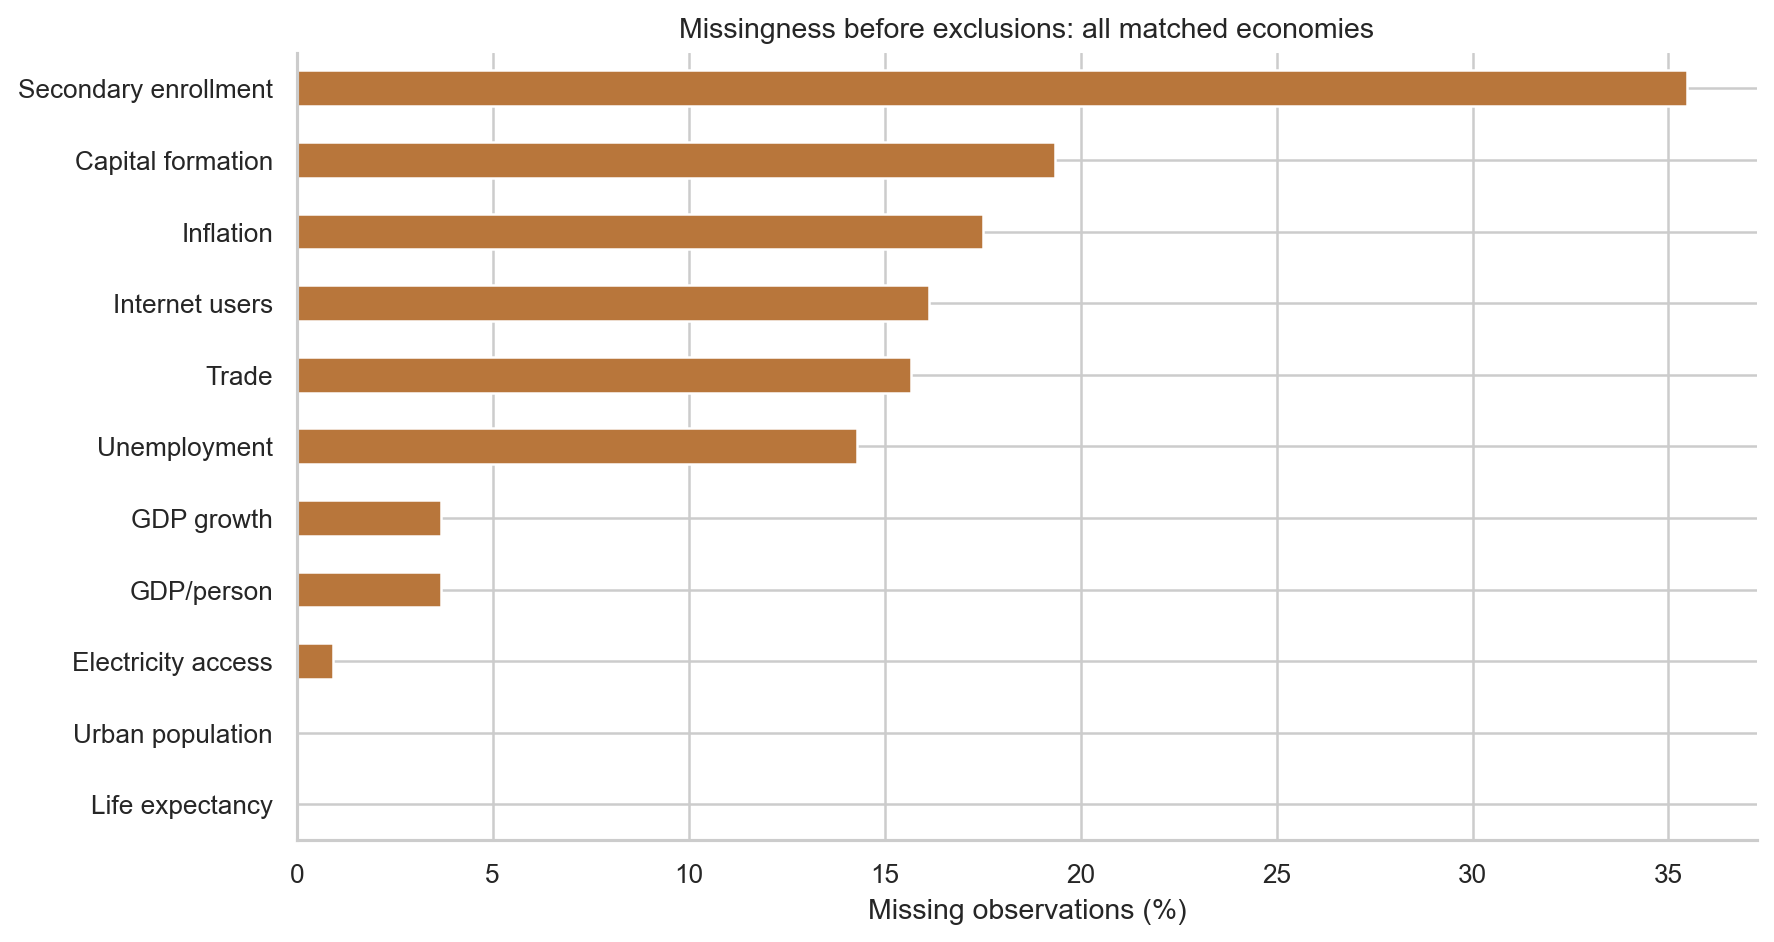

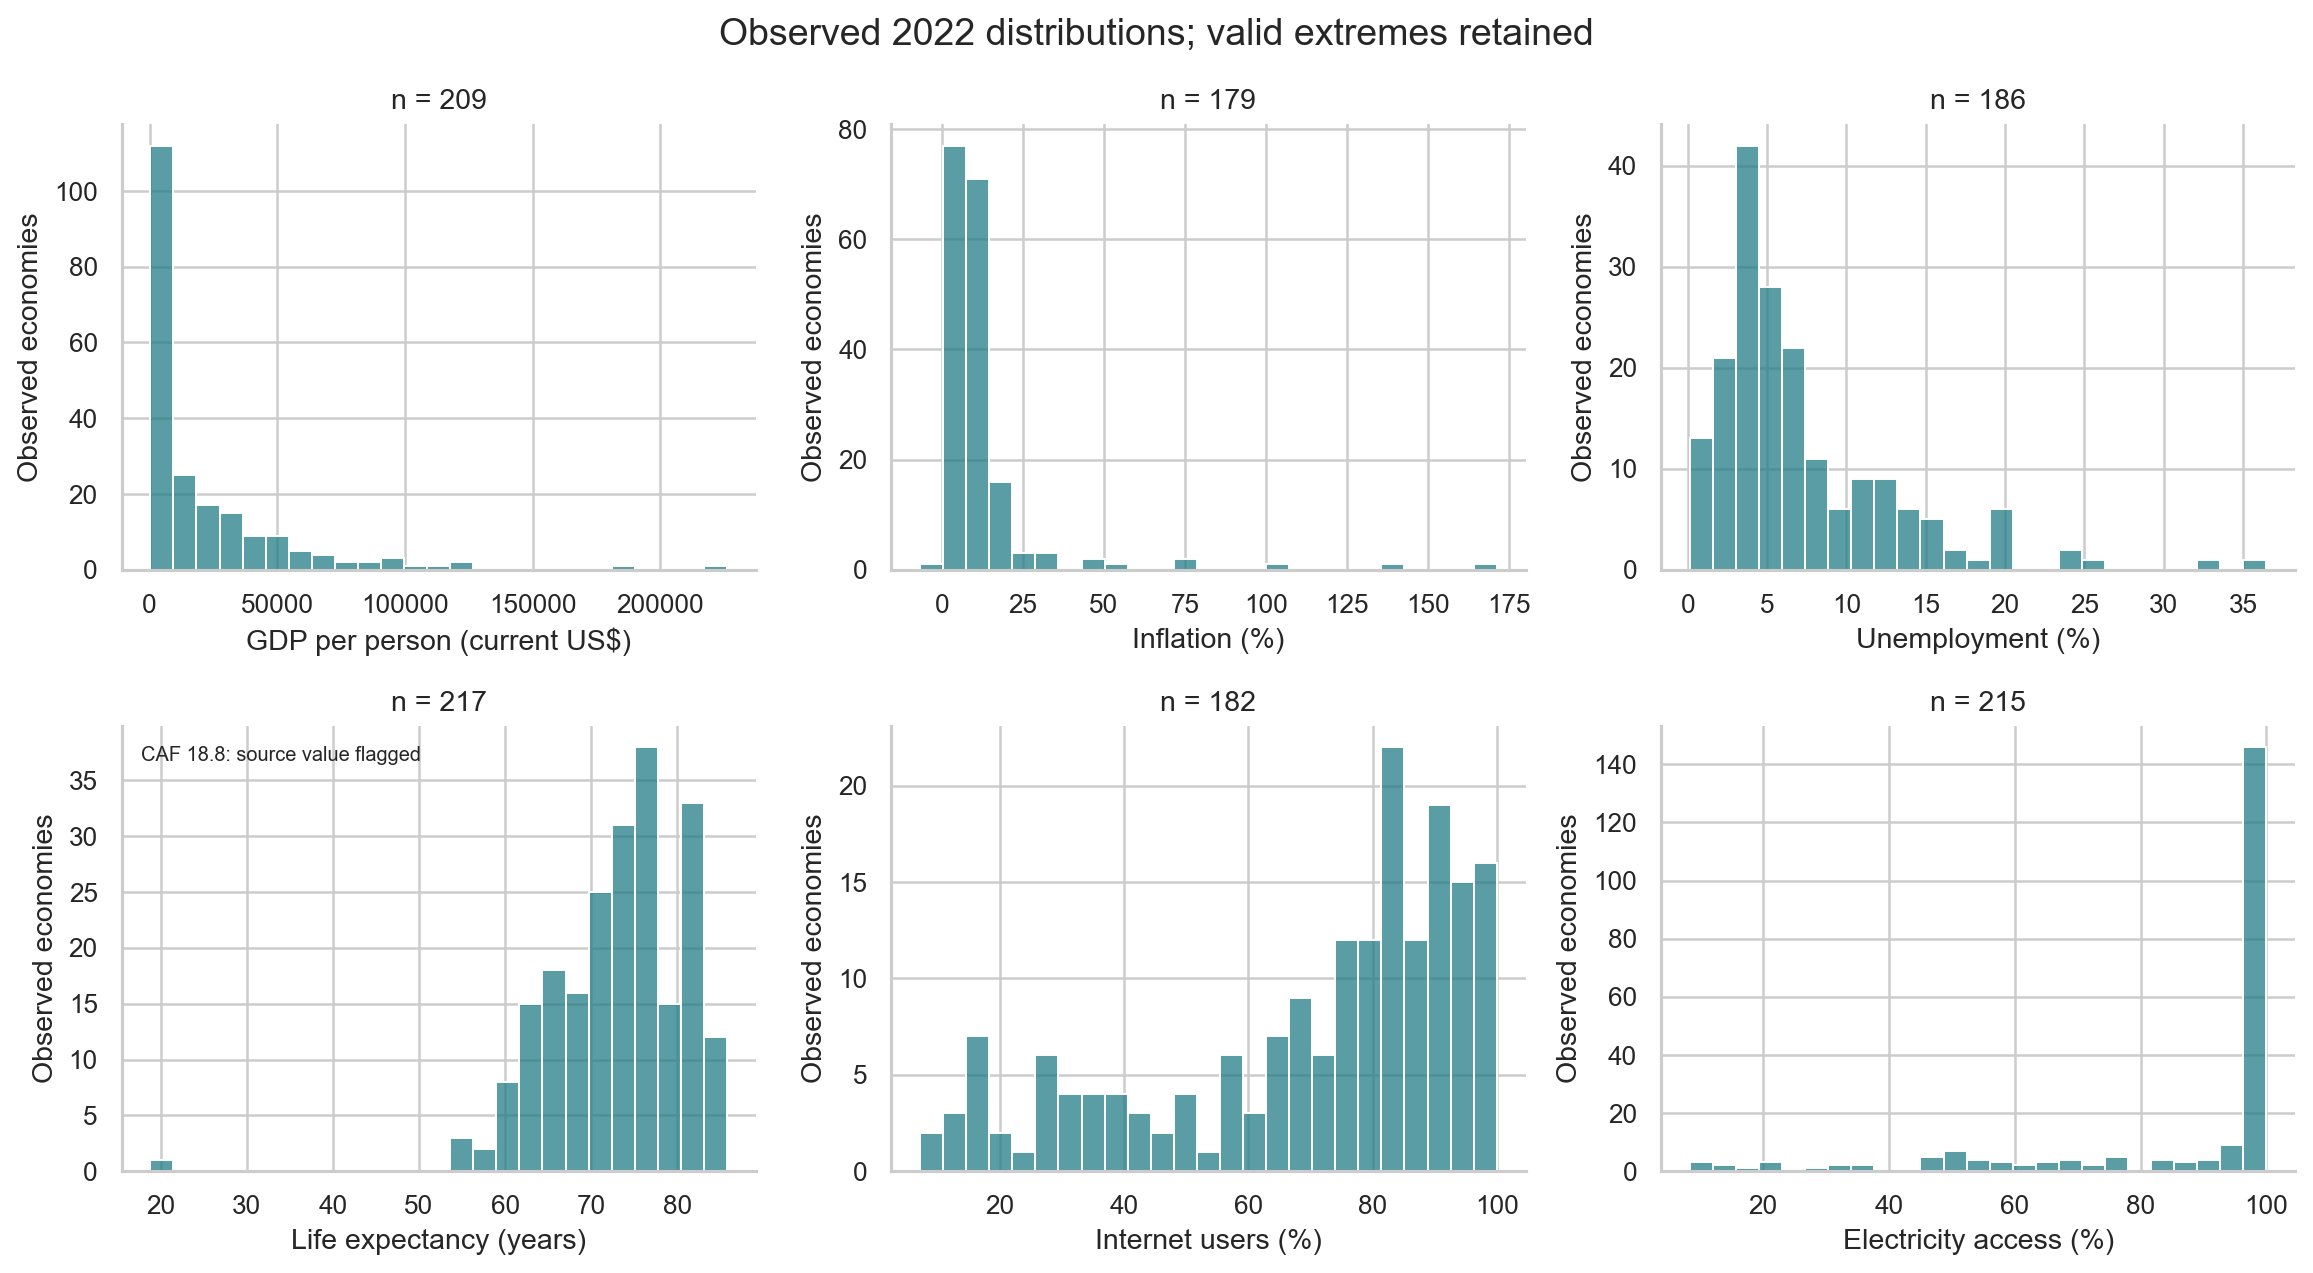

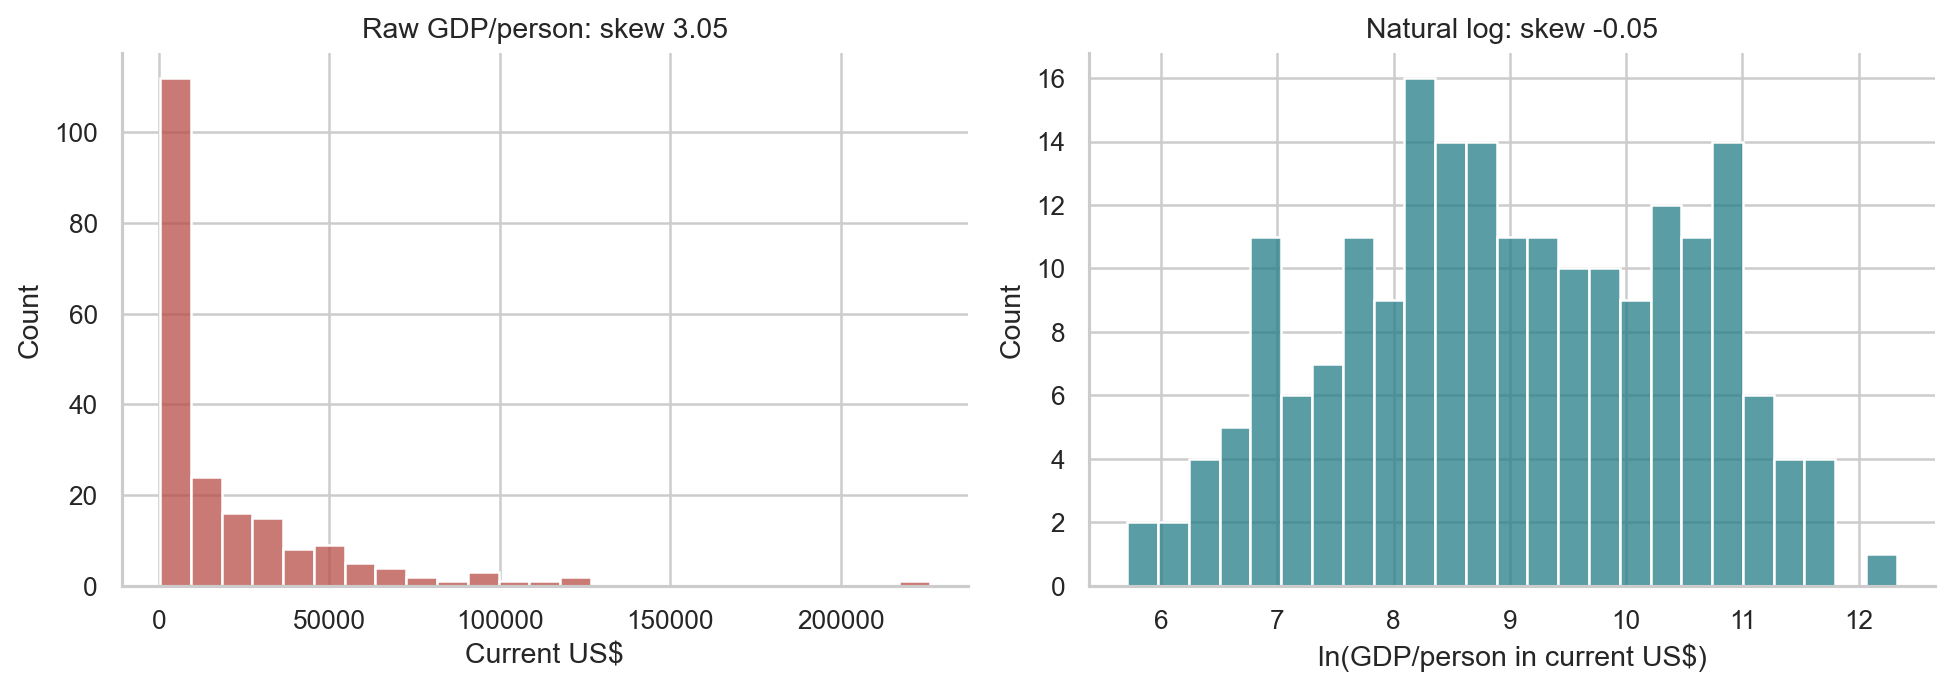

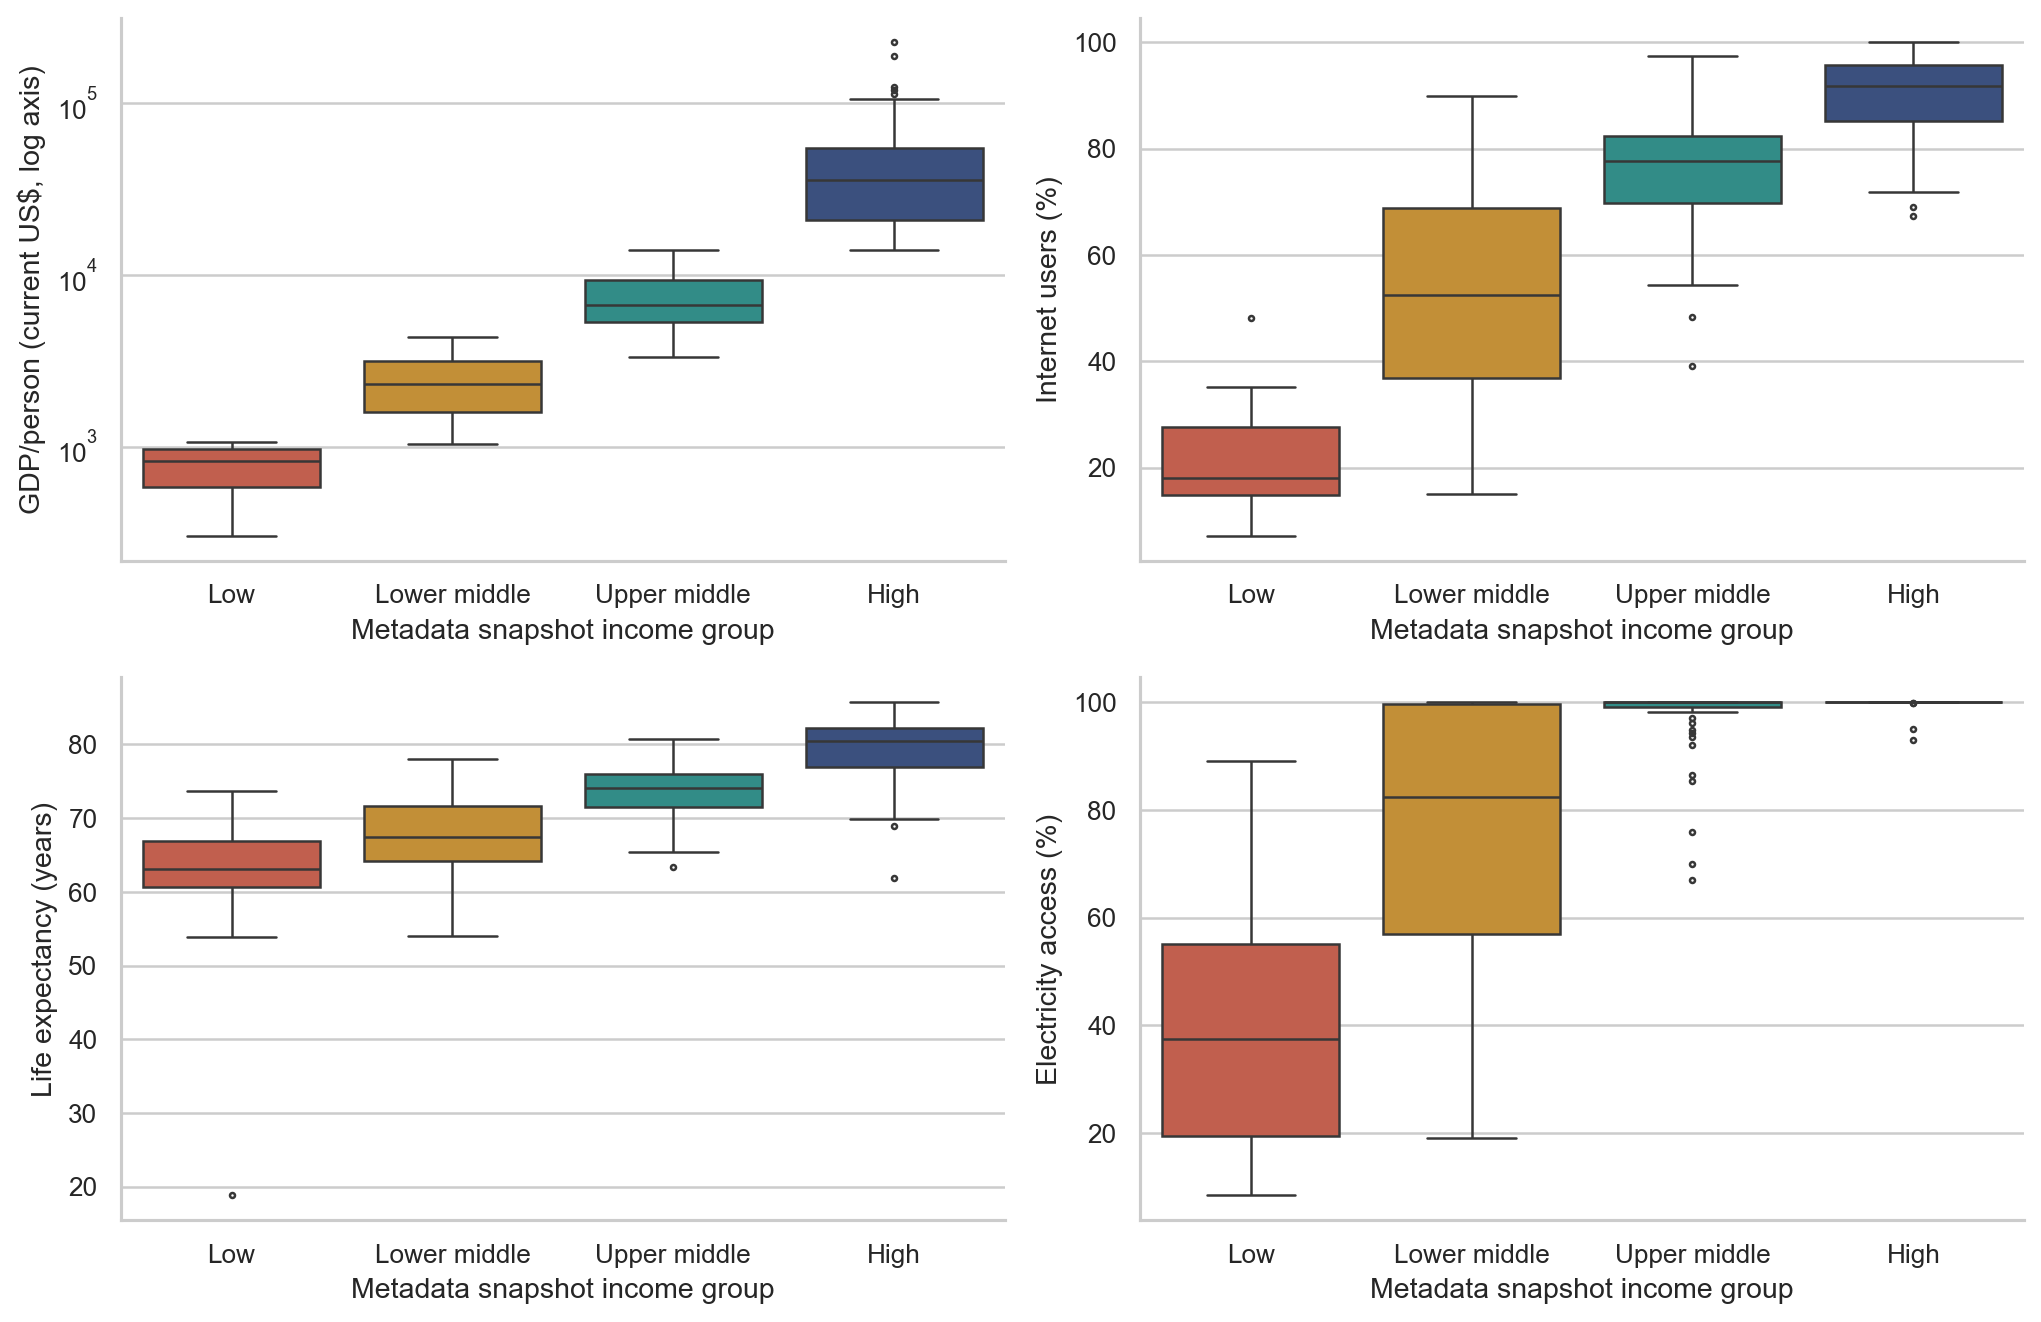

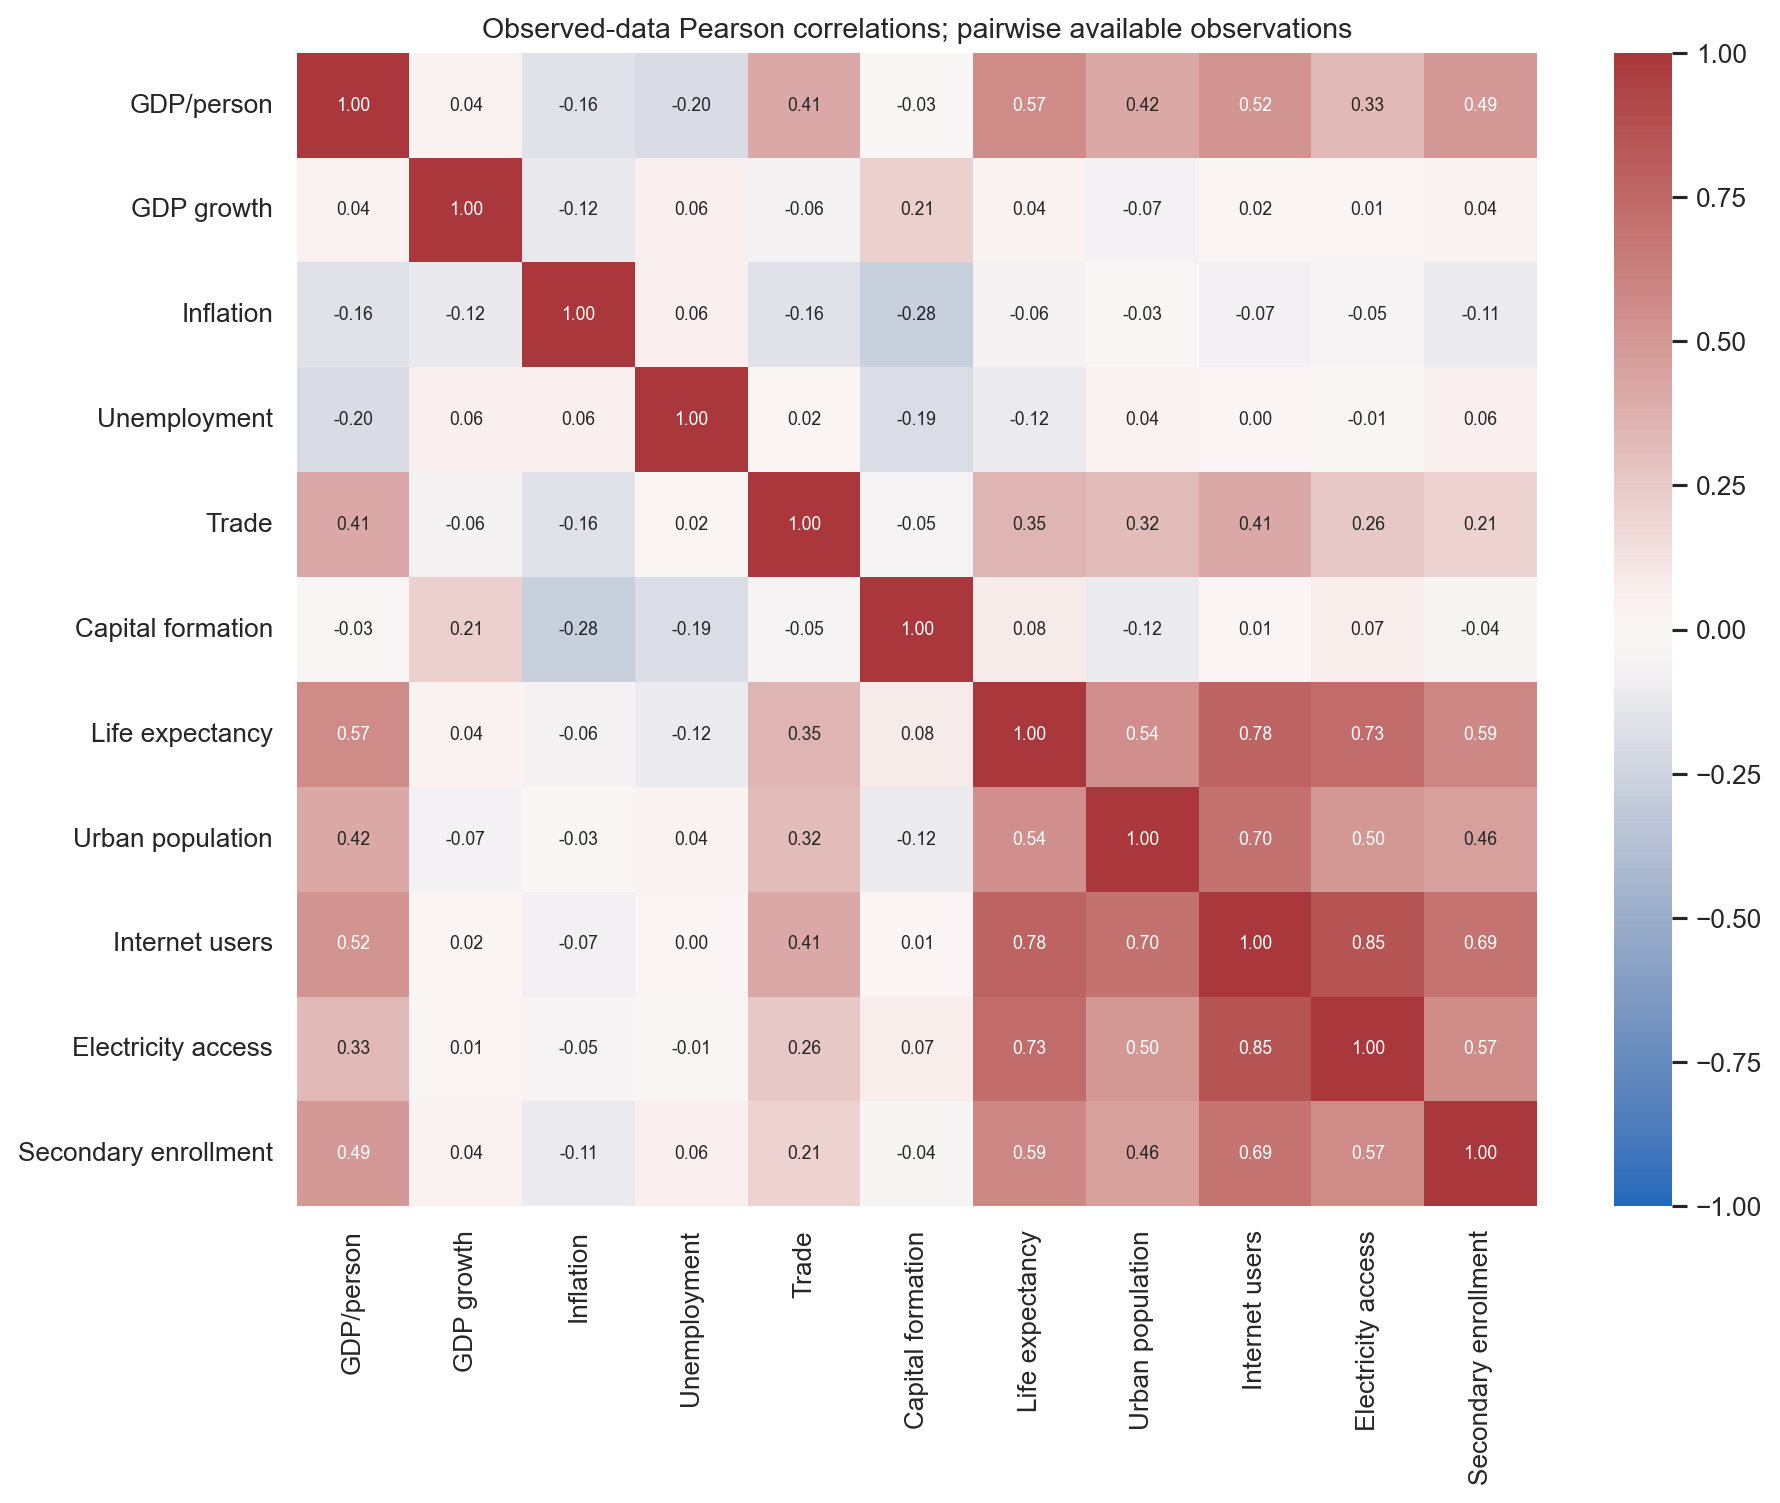

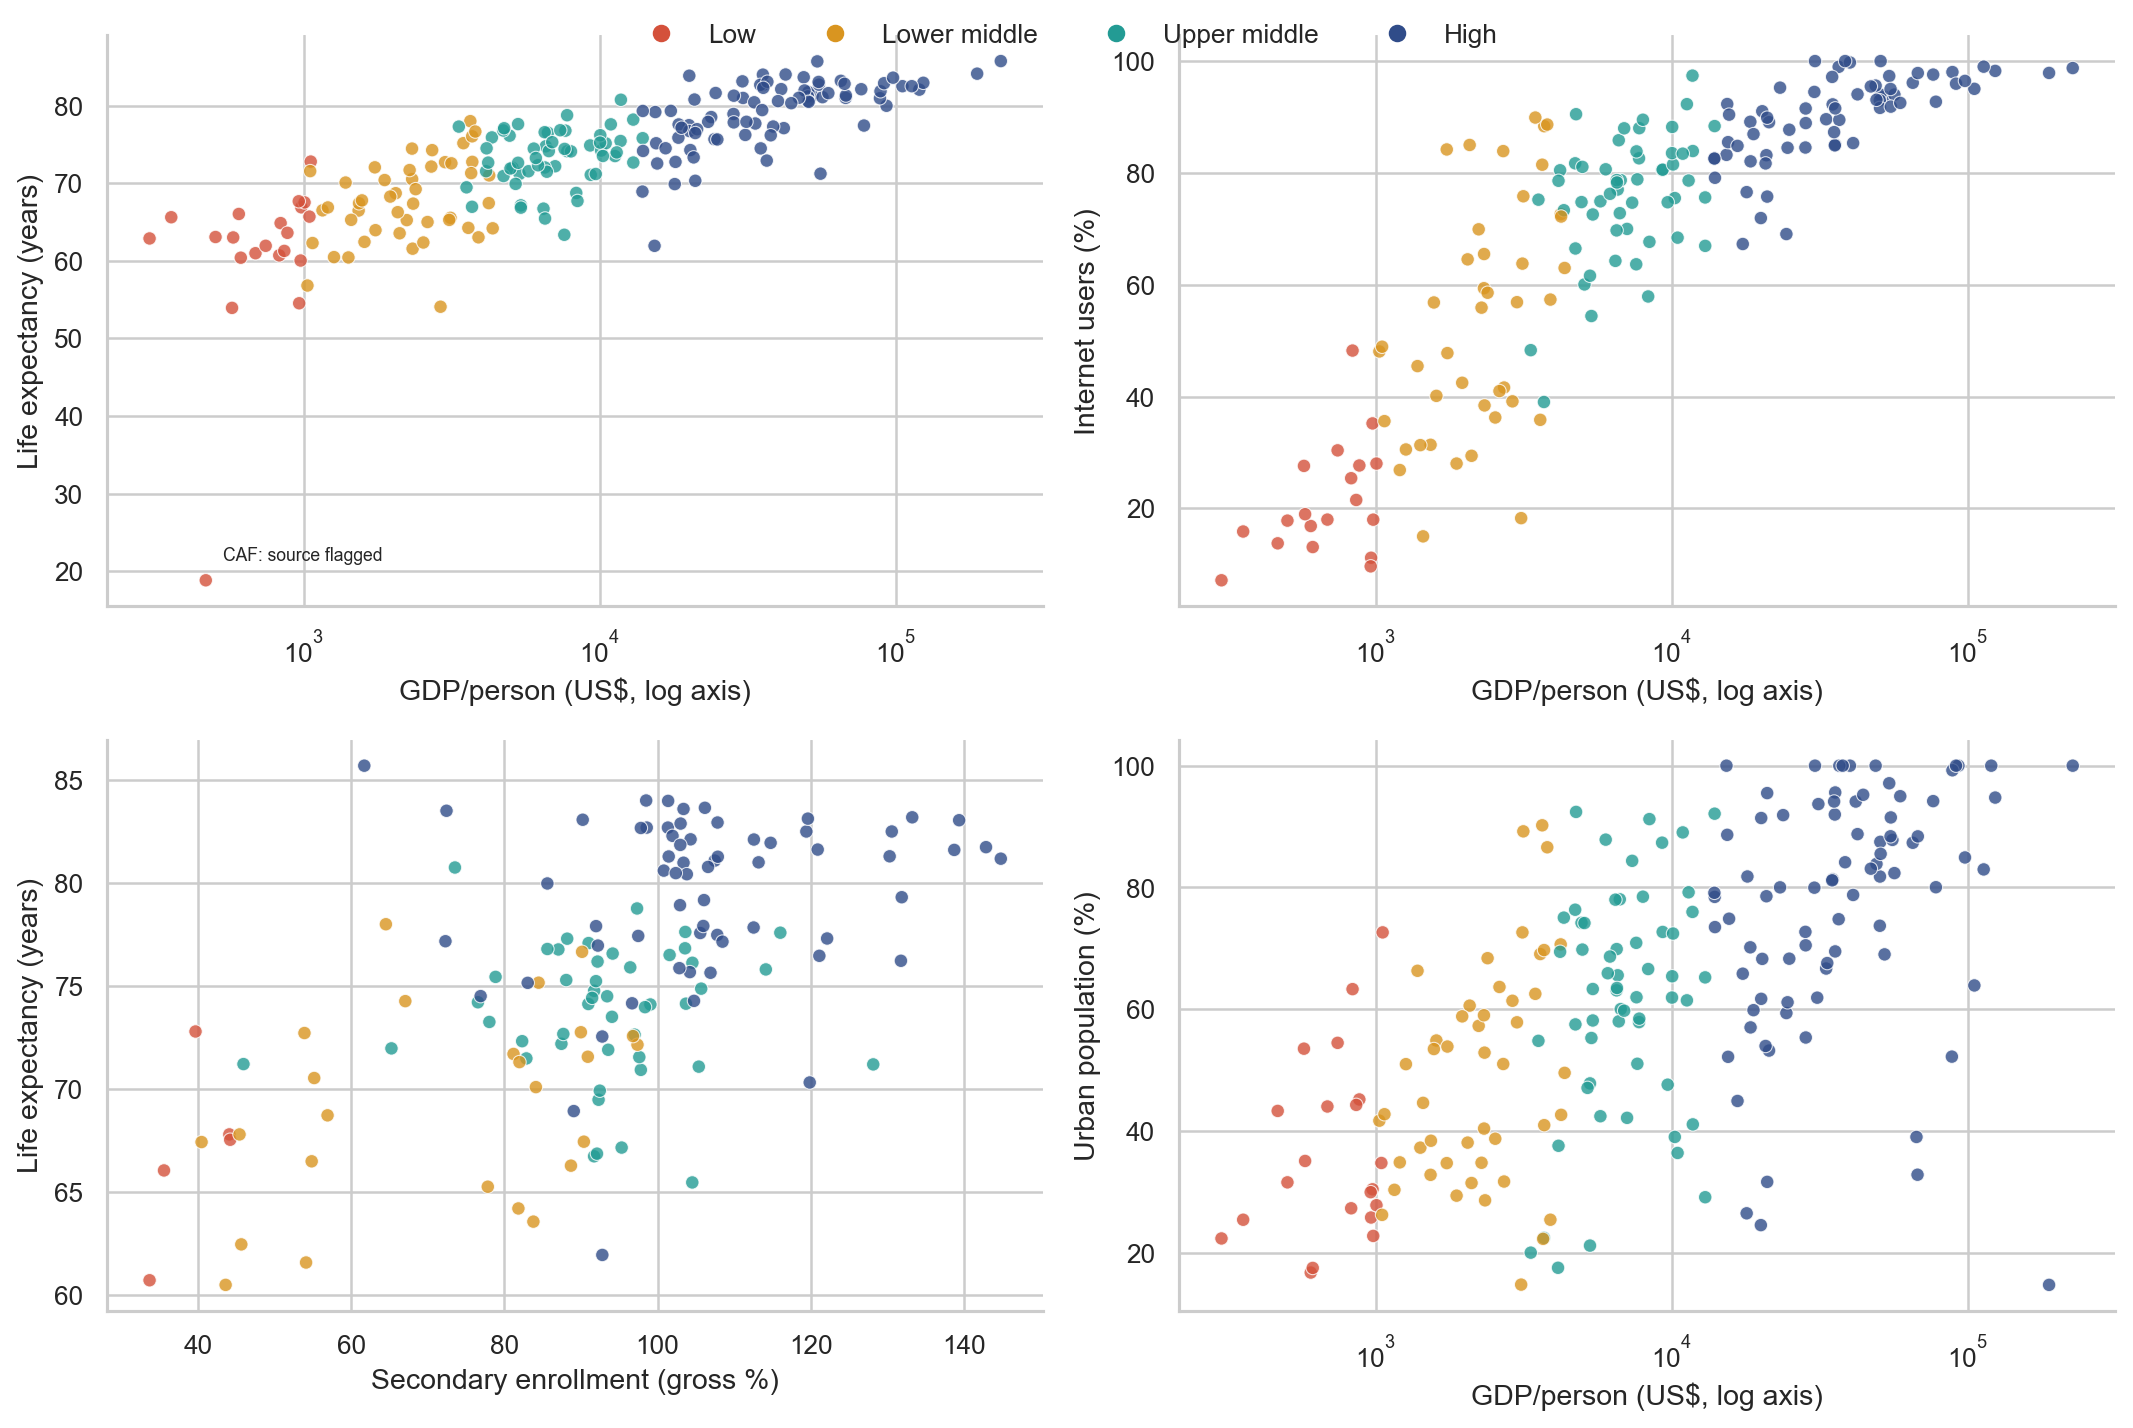

In [3]:
project.eda(state)
display(state['descriptive_statistics'].round(3))
display(state['quality_flags'])
show_figures('01_missingness', '02_required_distributions', '03_gdp_transform',
             '04_income_group_comparisons', '05_observed_correlations',
             '06_required_pairwise_relationships')


### Interpretation of the exploratory evidence

Income, longevity, connectivity and electricity tend to increase together, while countries within the same reference income group still differ. Electricity access clusters near 100% for many economies, so it has a ceiling effect. Growth and inflation include large country-specific extremes and need separate interpretation from the slower-moving development indicators.

Correlated development variables can partly repeat information; PCA provides an orthogonal representation, but it does not make feature selection or substantive interpretation automatic. Correlation does not establish a causal relationship. The source-quality observation is visible and labelled rather than silently removed from the EDA.


### 2.1 Observed correlations and redundant signals

The strongest observed pair is Internet use and electricity access: r=0.852 on 182 pairwise-observed economies. Other strong relationships include Internet use with life expectancy and with urbanization. The ranked table gives the actual sample size for every pair, so the coefficients are not mistaken for estimates based on 217 complete observations.

Standardization equalizes marginal scale, but strongly correlated indicators can still give their shared development signal more influence in Euclidean distance. PCA makes axes orthogonal without making substantive importance automatic.


In [4]:
display(state['strong_correlations'].head(8).round(4))


,feature_1,feature_2,pearson_r,n_observed_pairs
0,Internet_Users,Electricity_Access,0.8517,182
1,Life_Expectancy,Internet_Users,0.7786,182
2,Life_Expectancy,Electricity_Access,0.7337,215
3,Urban_Population,Internet_Users,0.6967,182
4,Internet_Users,Secondary_Enrollment,0.6908,128
5,Life_Expectancy,Secondary_Enrollment,0.5853,140
6,GDP_PC,Life_Expectancy,0.5703,209
7,Electricity_Access,Secondary_Enrollment,0.5683,140


## 3. Numerical preprocessing and PCA

Sequence: **ln(GDP per capita) -> global median imputation -> standardization -> correlation analysis -> PCA**. Standardization uses the mean and standard deviation of the retained cross-sectional sample. The objective is descriptive clustering of this sample, not supervised prediction; train/validation/test splits from regression/classification are not imported without a prediction objective. Sensitivity runs refit every preprocessing step on their own samples.

PCA keeps the smallest number of components whose cumulative explained variance reaches 80%. This is a transparent compression rule rather than a claim that 80% is universally optimal. Coefficient tables and fitted preprocessing parameters are exported. The values called coefficients here are normalized PCA eigenvector entries, not correlations between PCs and variables.


PCA: 6 components retain 84.67%; first two retain 51.13%.
Preceding 5 PCs retain 77.54%; this is below the configured threshold.
Coefficient signs are arbitrary. Large absolute coefficients identify variables defining each direction.
                        PC1    PC2    PC3
GDP_PC                0.450  0.040  0.028
GDP_Growth            0.012  0.380  0.579
Inflation            -0.074 -0.518 -0.217
Unemployment         -0.023 -0.341  0.714
Trade                 0.232 -0.043  0.033
Capital_Formation     0.009  0.651 -0.098
Life_Expectancy       0.424  0.059 -0.100
Urban_Population      0.368 -0.182  0.005
Internet_Users        0.449 -0.046 -0.037
Electricity_Access    0.404  0.030 -0.087
Secondary_Enrollment  0.238 -0.061  0.279


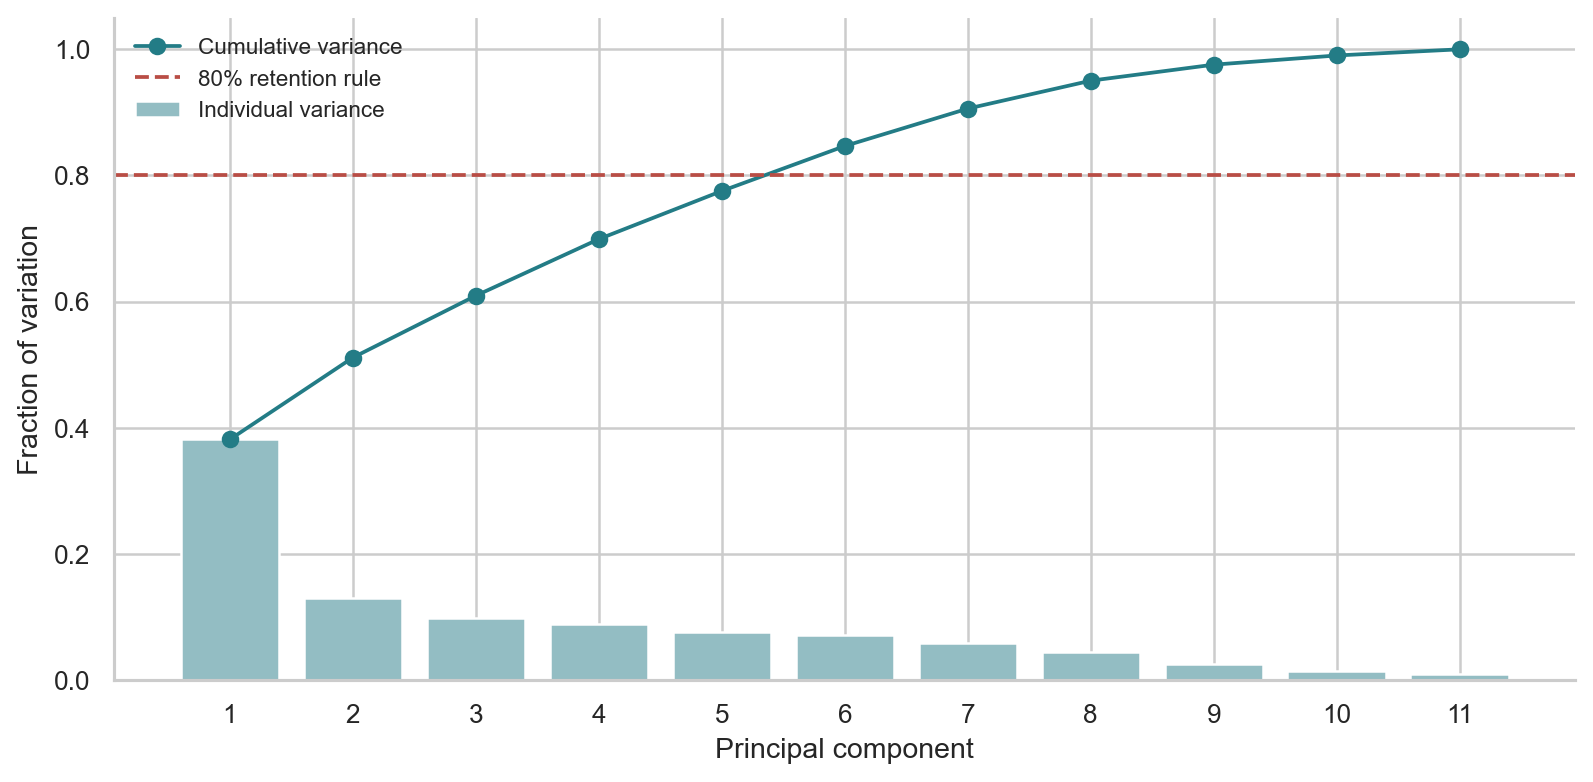

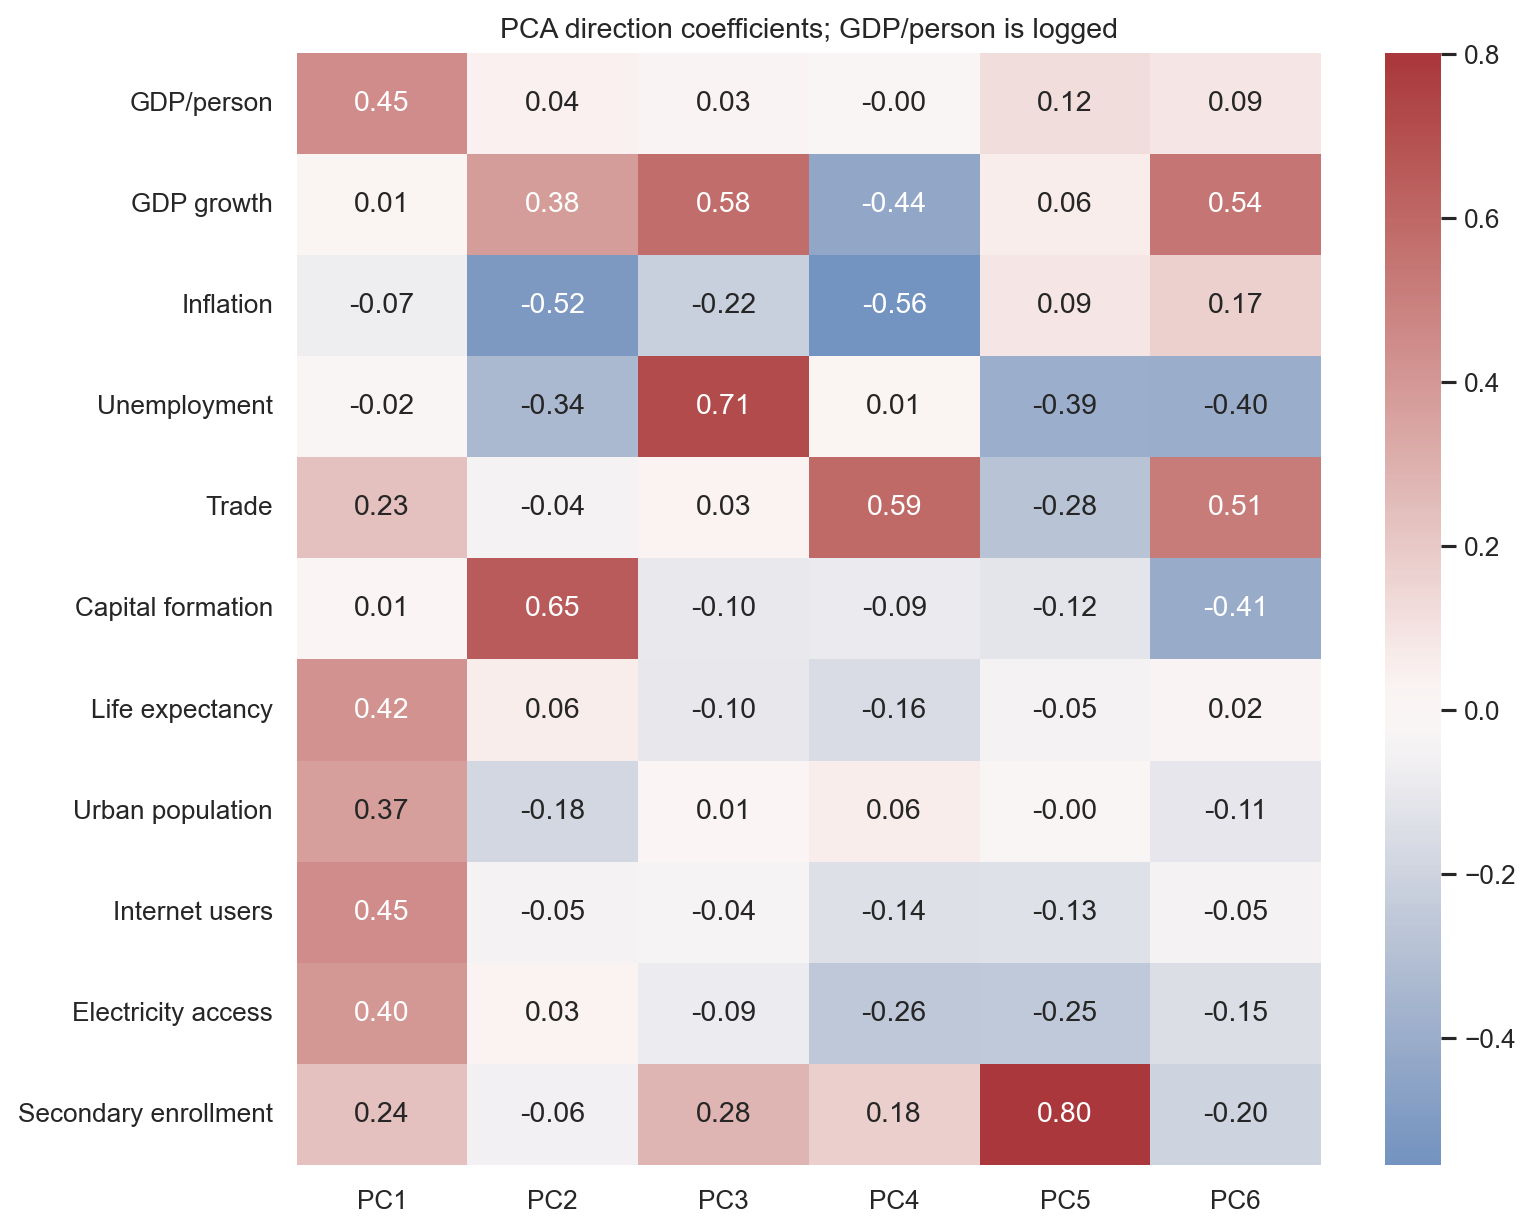

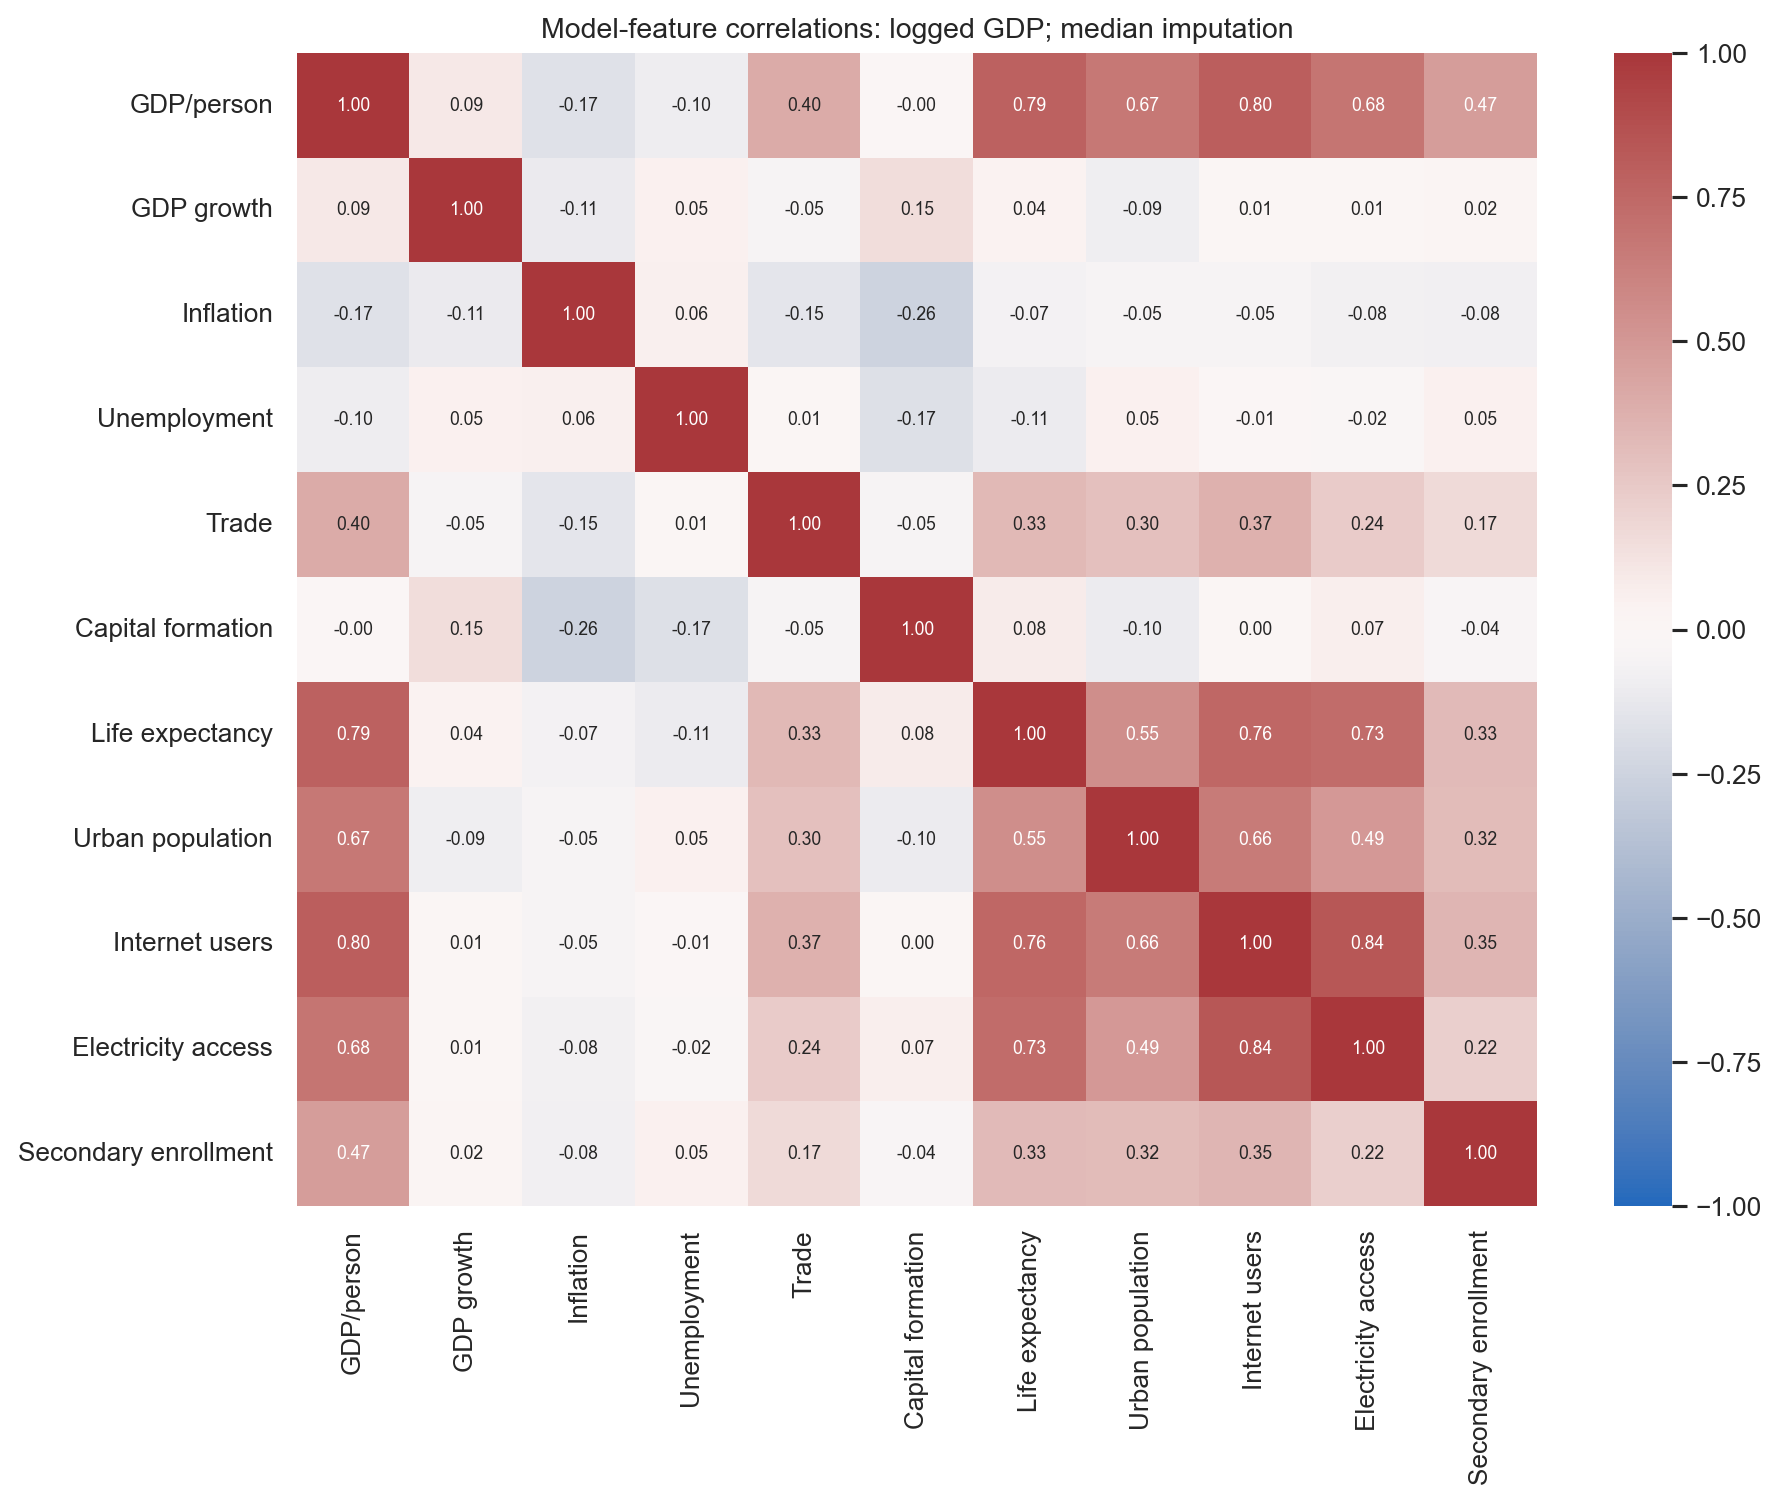

,PC,explained_variance_ratio,cumulative_variance
1,2,0.129747,0.511262
4,5,0.076300,0.775384
5,6,0.071285,0.846669


In [5]:
project.preprocess(state)
show_figures('07_pca_variance', '08_pca_coefficients', '09_model_correlations')

variance = pd.read_csv(ROOT / 'outputs/tables/10_pca_variance.csv')
display(variance.loc[variance.PC.isin([2, 5, 6])].round(6))


In [6]:
loadings = state['loadings']
for component in ['PC1', 'PC2', 'PC3']:
    print(component, 'largest absolute coefficients:')
    print(loadings[component].sort_values(key=abs, ascending=False).head(5).round(3))
display(Markdown('Interpret components from their large coefficients, signs and underlying units. '
                 'PC1 describes a broad development/infrastructure direction. '
                 'Later components distinguish macroeconomic and labour-market differences. '
                 'The sign of an entire PC can reverse without changing the solution; '
                 'these are descriptive directions, not causal or welfare rankings.'))


PC1 largest absolute coefficients:
GDP_PC                0.450
Internet_Users        0.449
Life_Expectancy       0.424
Electricity_Access    0.404
Urban_Population      0.368
Name: PC1, dtype: float64
PC2 largest absolute coefficients:
Capital_Formation    0.651
Inflation           -0.518
GDP_Growth           0.380
Unemployment        -0.341
Urban_Population    -0.182
Name: PC2, dtype: float64
PC3 largest absolute coefficients:
Unemployment            0.714
GDP_Growth              0.579
Secondary_Enrollment    0.279
Inflation              -0.217
Life_Expectancy        -0.100
Name: PC3, dtype: float64


Interpret components from their large coefficients, signs and underlying units. PC1 describes a broad development/infrastructure direction. Later components distinguish macroeconomic and labour-market differences. The sign of an entire PC can reverse without changing the solution; these are descriptive directions, not causal or welfare rankings.

### Meaning of the six retained components

In the frozen main fit, PC1 puts large coefficients on log GDP per capita, Internet usage, life expectancy and electricity access, describing a broad development/infrastructure direction. PC2 contrasts capital formation and GDP growth with inflation and unemployment. PC3 has large coefficients on unemployment and growth together; it captures a residual statistical direction, not a claim that growth causes unemployment. PC4 contrasts trade with inflation and growth. PC5 is dominated by secondary-school enrollment, with unemployment contributing in the opposite direction. PC6 contrasts growth and trade with capital formation and unemployment.

These interpretations use relative signs and magnitudes of the displayed coefficients. Flipping every coefficient in a component leaves the interpretation of its contrasts and the PCA geometry unchanged. Variance retention does not make a component a welfare index.


## 4. K-means and hierarchical clustering

K-means tests k=2 through 8 with seed 42 and 50 initializations. The primary selection rule is the largest mean silhouette score over this finite candidate range; the elbow, group sizes and interpretability provide context. We do not force four groups to match the four income categories.

Ward agglomerative clustering uses **the same preprocessed countries, retained PCA dimensions and selected k**. Ward successively merges groups with the smallest increase in within-group variance. It is included under the professor's explicit permission for hierarchical libraries. The dendrogram overview marks the chosen cut. Both models operate in six dimensions; the two-PC scatter plots are visual summaries that omit variation used by the models.

### 4.1 Cluster-count decision and Ward cut

The inertia curve starts at k=1. Silhouette scores start at k=2. In the frozen fit the k=1 to k=2 inertia drop is 31.71%, followed by 13.45% from k=2 to k=3; this supports a broad early split without proving a unique elbow. k=2 has the largest silhouette (0.357). The runner-up k=7 scores 0.255 and includes a singleton; its smaller score and very small cluster offer no reason to replace the primary two-group summary. Both methods use identical six-PC geometry and k to isolate algorithm differences. Ward is cut at height 25.495, approximately 25.50, between the last two merge heights; the line and height are shown on the readable tree.


Both methods use the same 6-PC coordinates and k=2 to compare algorithms without changing inputs; Ward cut height=25.4950.
K-means selected k=2 over [2, 3, 4, 5, 6, 7, 8] by highest silhouette; inspect sizes and elbow as context.
Inertia including k=1:
  k  inertia  drop_from_previous  drop_percent_previous
 1 1909.238                 NaN                    NaN
 2 1303.838             605.400                 31.709
 3 1128.452             175.386                 13.452
 4  986.432             142.020                 12.585
 5  861.697             124.735                 12.645
 6  785.772              75.925                  8.811
 7  709.847              75.925                  9.662
 8  640.062              69.784                  9.831
Silhouette runner-up:
  k  inertia  silhouette  smallest_cluster  largest_cluster
 7 709.8467      0.2552                 1               76
 k   inertia  silhouette  smallest_cluster  largest_cluster
 2 1303.8376      0.3572                60        

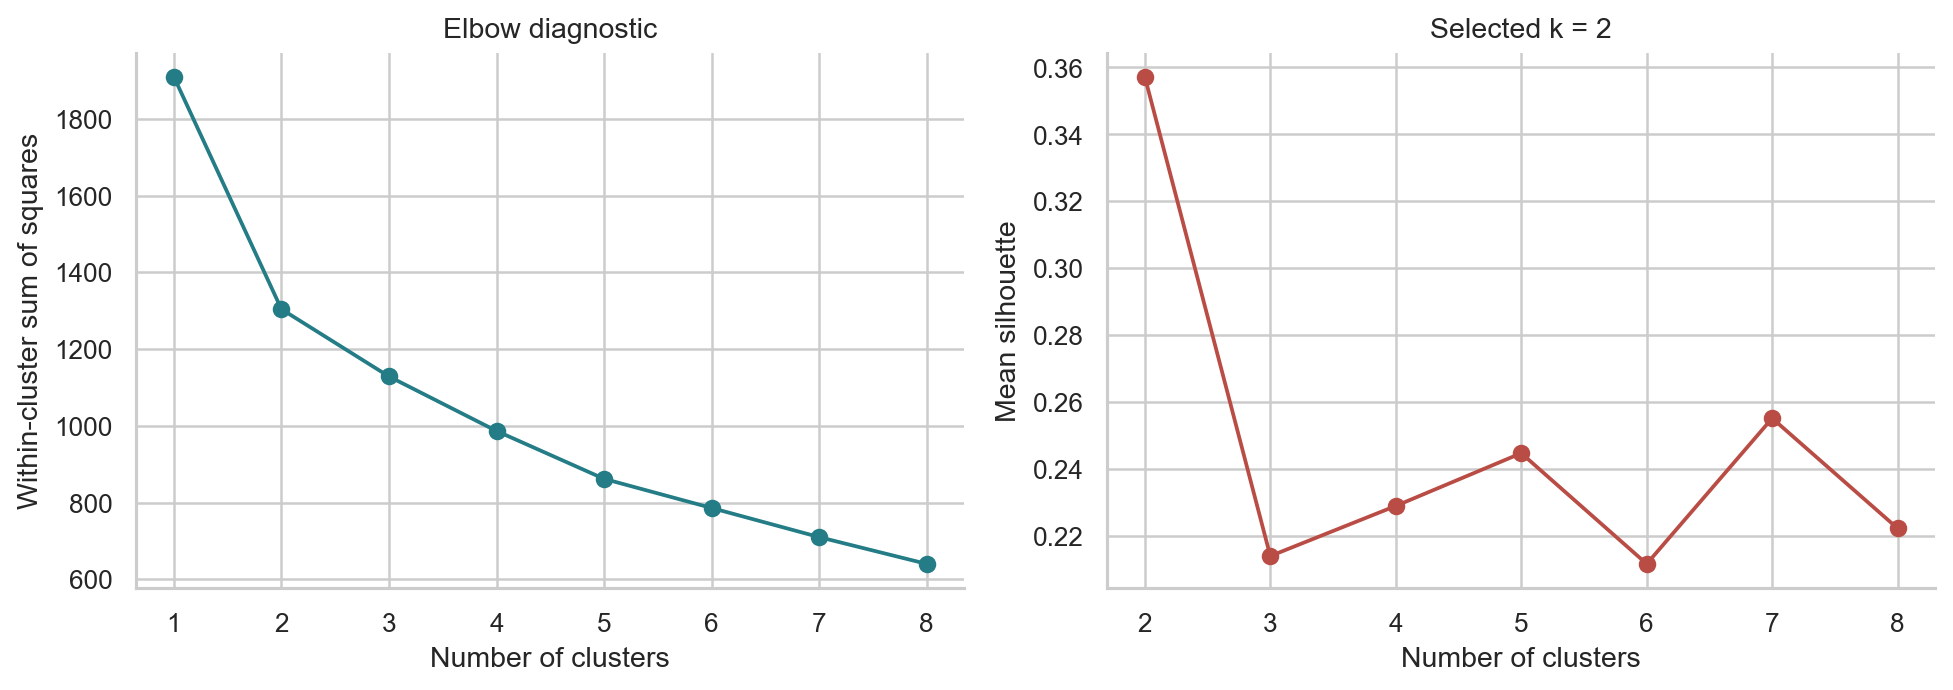

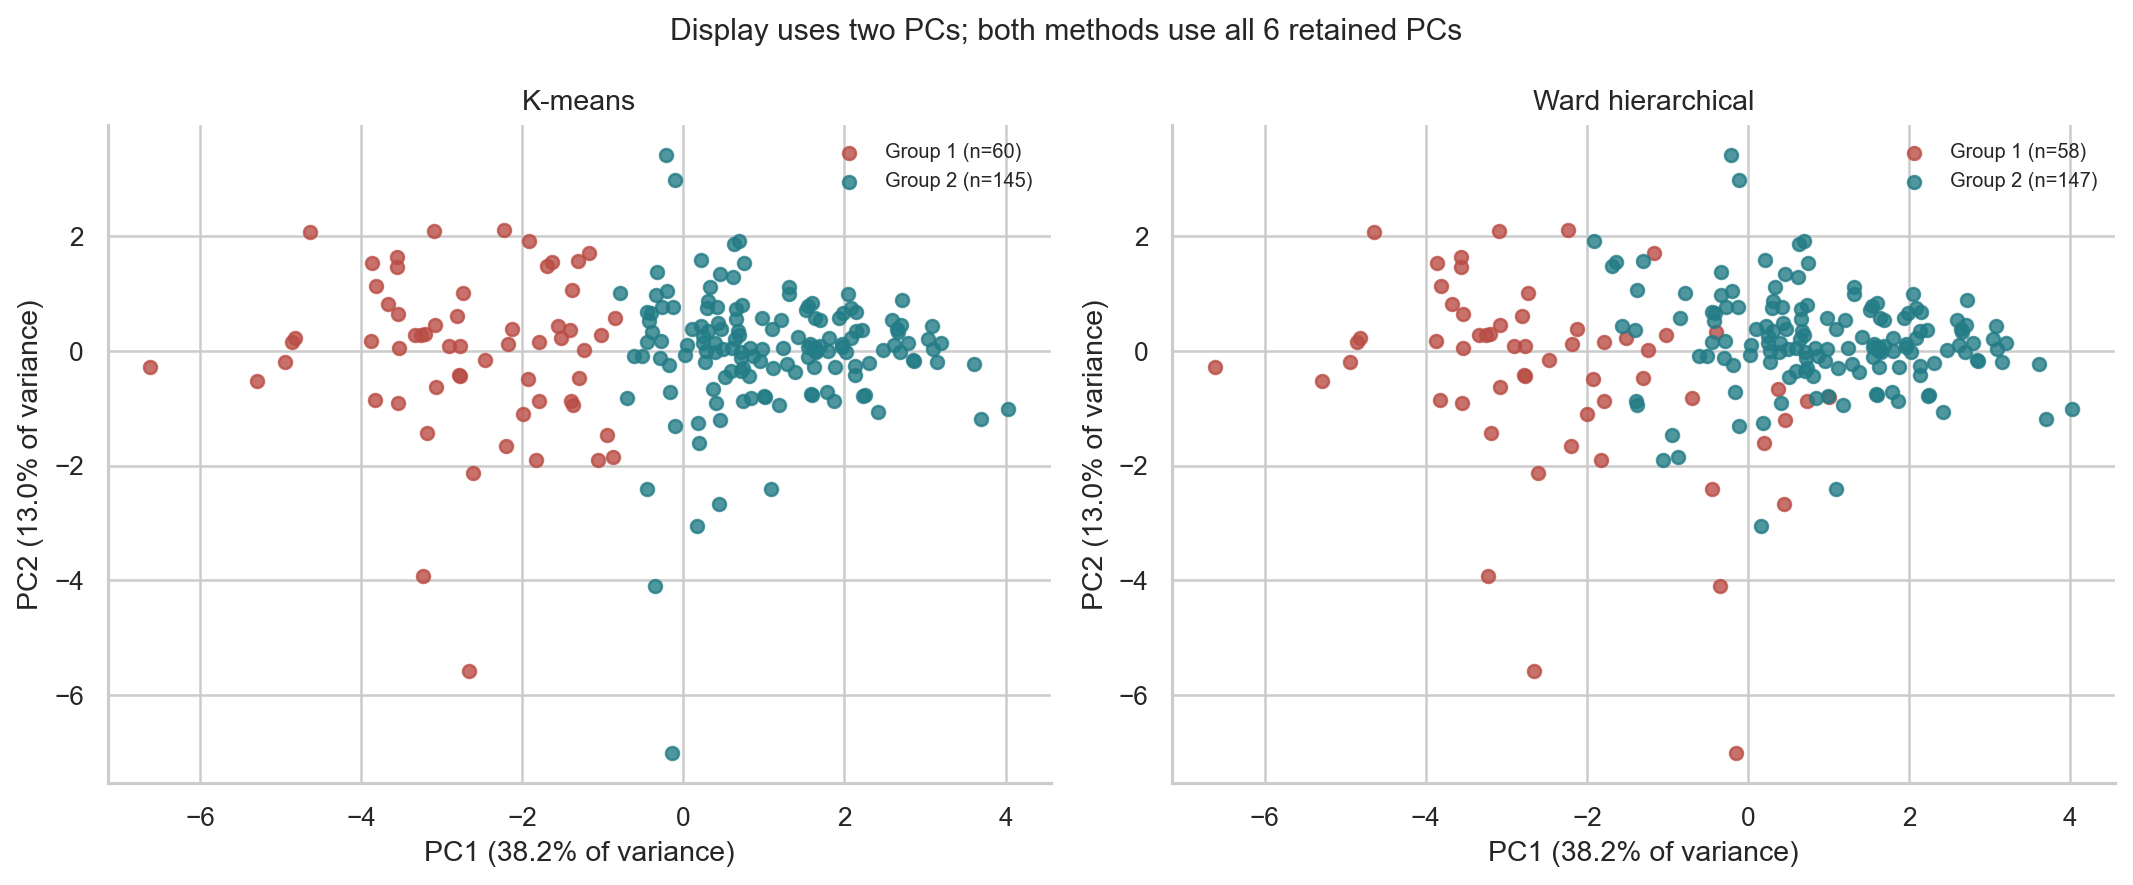

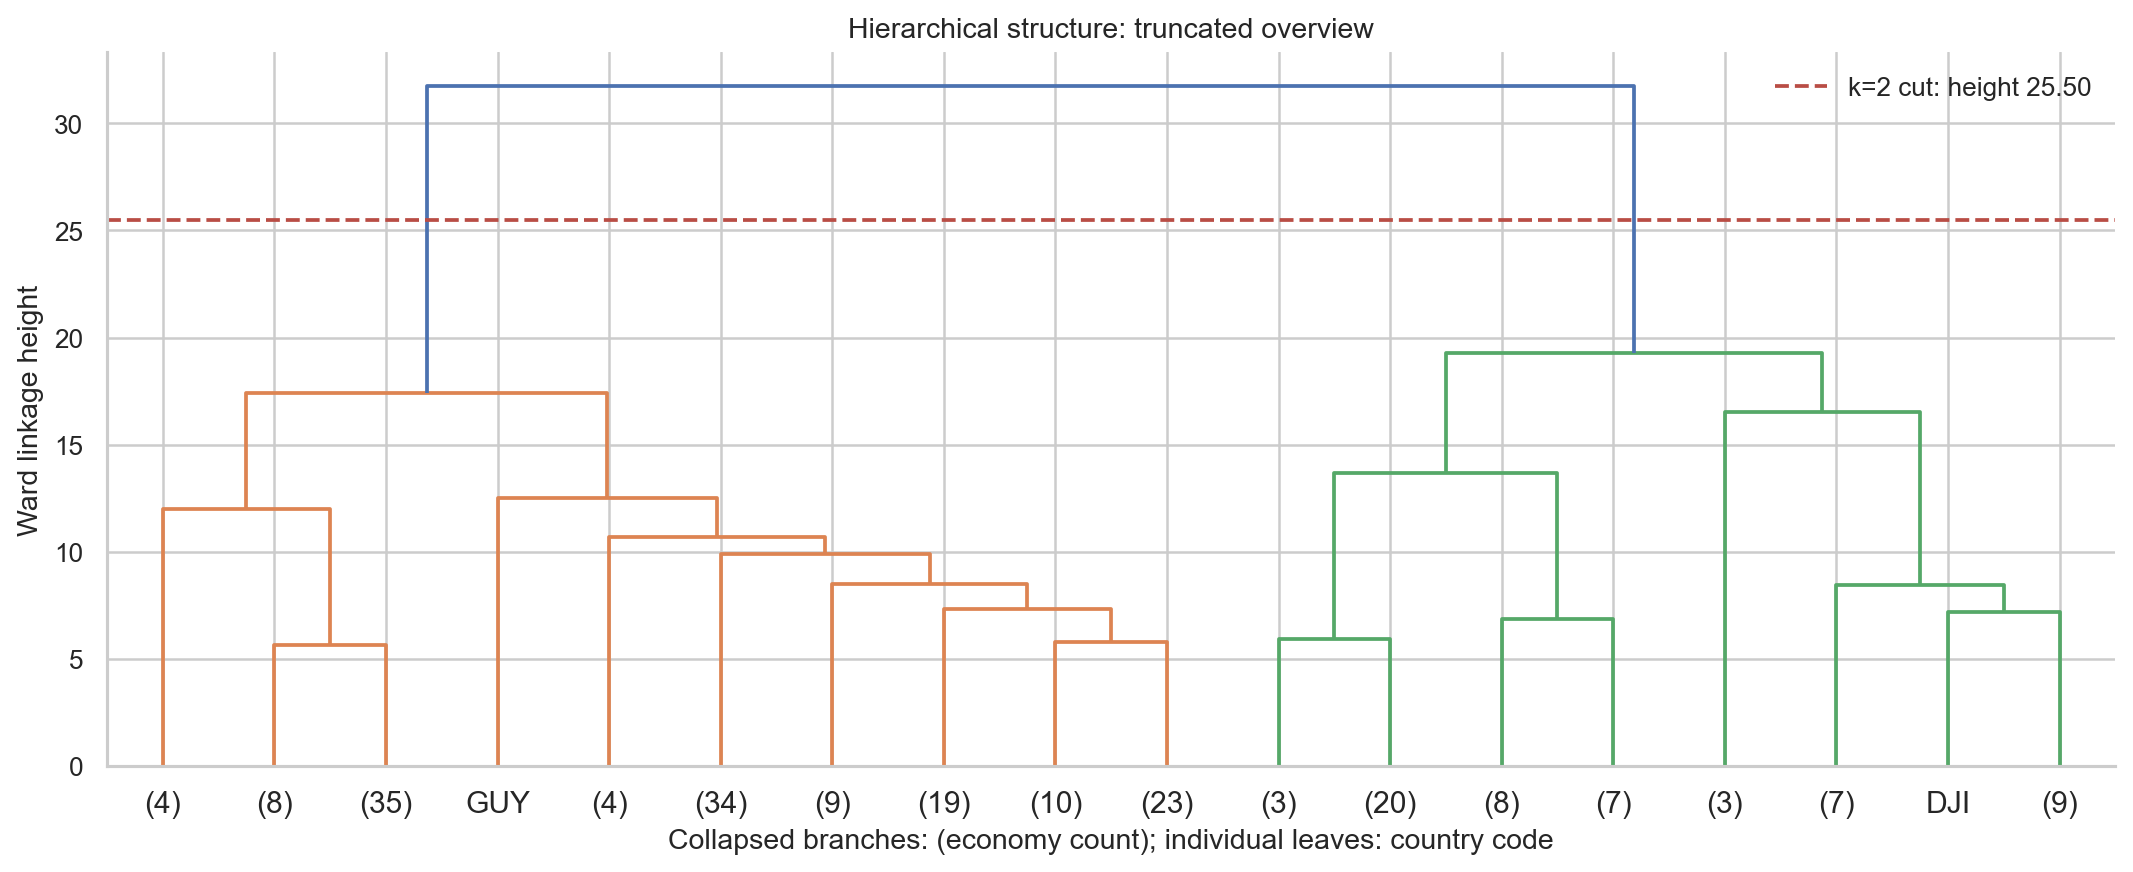

In [7]:
with threadpool_limits(limits=1):
    project.clustering(state)
show_figures('10_cluster_count_selection', '11_pca_cluster_comparison',
             '12_ward_dendrogram_overview')


## 5. Socioeconomic interpretation, external comparisons and unusual economies

Cluster numbers are names rather than ranks. For readability they are ordered by observed median GDP per capita after fitting; that naming step does not feed labels or GDP information into a model that did not use it. Describe groups using original-unit medians and observation counts as well as standardized profiles.

Income/region comparisons are counts and clearly normalized percentages. ARI/NMI compare partitions independently of arbitrary label numbering and are not classification accuracy. A difference list based on GDP-ordered names is also exported, with that naming convention explicit.

Large distance to the centroid identifies unusual profiles. Negative individual silhouette identifies ambiguity between clusters; these are distinct properties. The country table exports both, within-cluster distance percentiles, observed feature values and imputation flags. Feature deviations are descriptive in standardized original-feature space and are not an exact decomposition of PCA-space distance.


External comparison: 2022 indicators vs 2026-11-23 metadata; agreement, not accuracy.
algorithm reference_label   n    ARI    NMI  indicator_year metadata_snapshot_date
  K-means     IncomeGroup 205 0.3190 0.4057            2022             2026-11-23
  K-means          Region 205 0.1725 0.2452            2022             2026-11-23
     Ward     IncomeGroup 205 0.2601 0.3361            2022             2026-11-23
     Ward          Region 205 0.1639 0.2477            2022             2026-11-23
Algorithm disagreement and negative within-model silhouette answer different questions. Case details exported with per-field flags.
Original-unit cluster medians (observed values only; per-feature counts exported):
                  GDP_PC  GDP_Growth  Inflation  Unemployment  Trade  Capital_Formation  Life_Expectancy  Urban_Population  Internet_Users  Electricity_Access  Secondary_Enrollment
KMeans_Cluster                                                                                         

,method,k,silhouette,sizes
0,K-means,2,0.3572,1:60; 2:145
1,Ward,2,0.3400,1:58; 2:147


Ward_Cluster,1,2
KMeans_Cluster,,
1,47,13
2,11,134


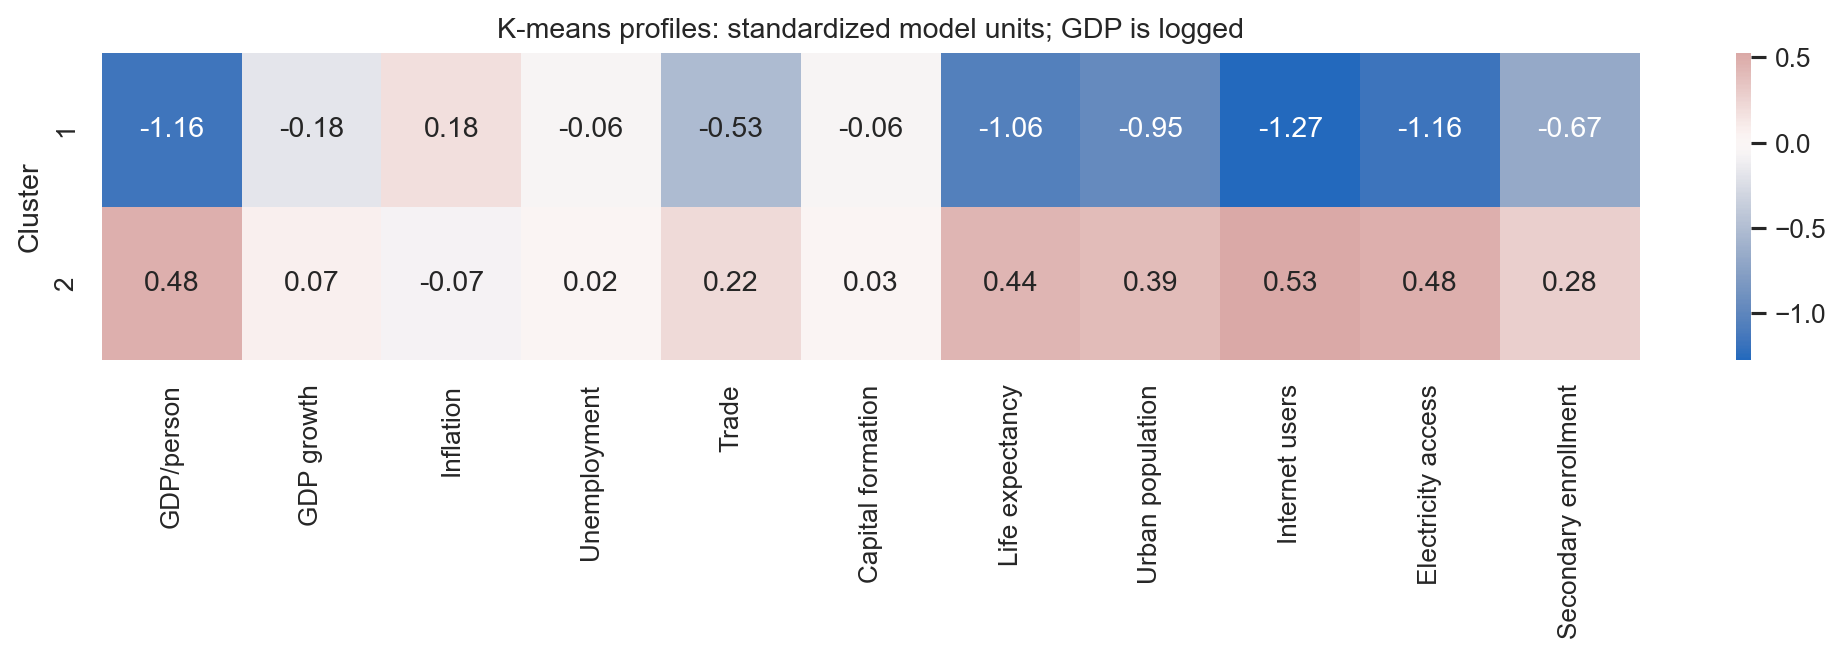

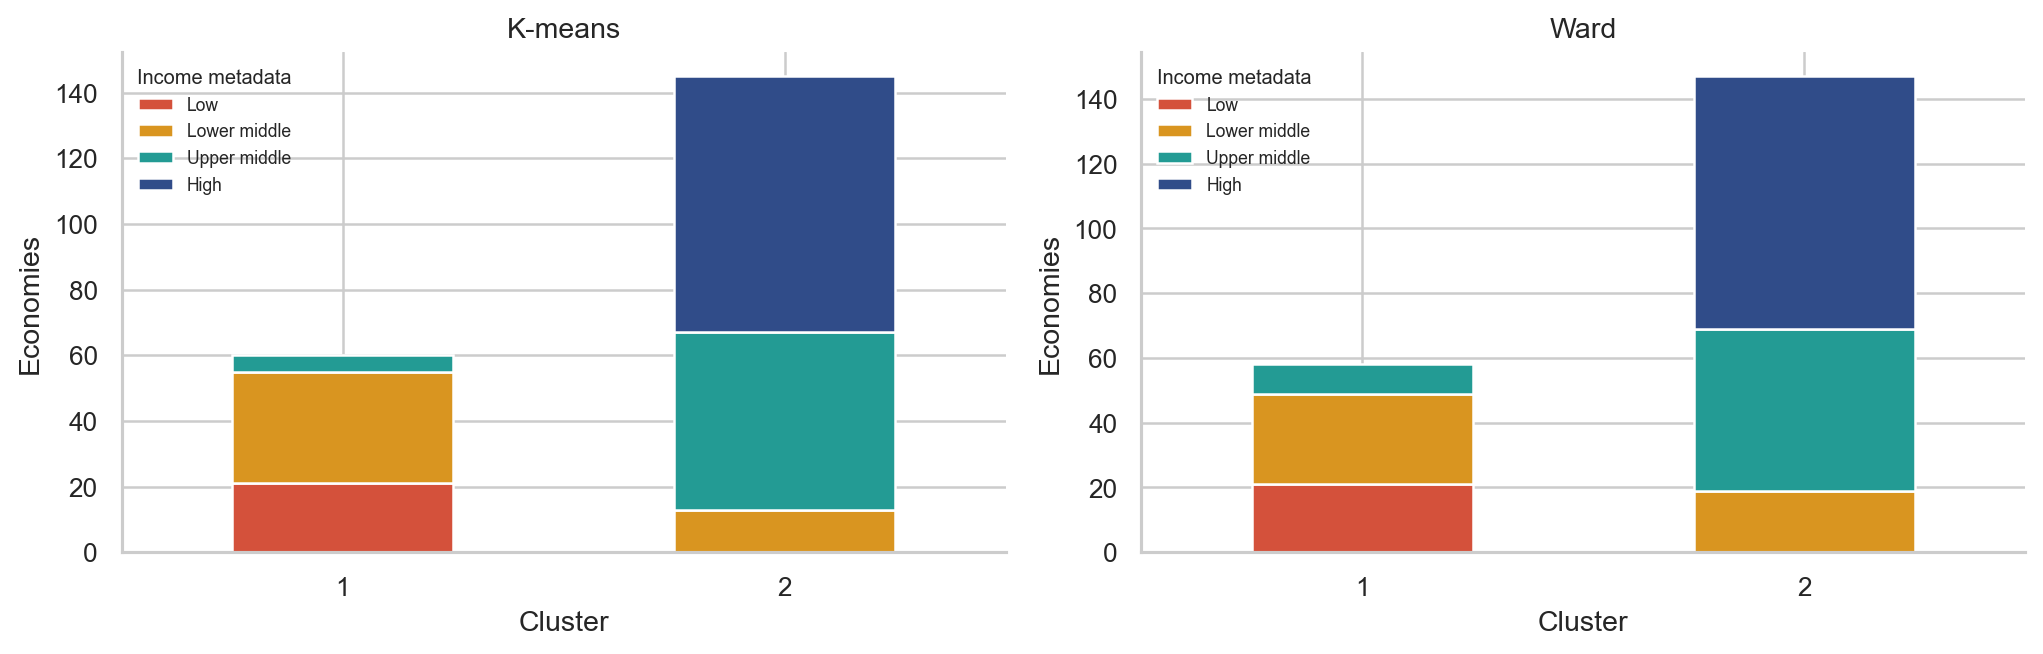

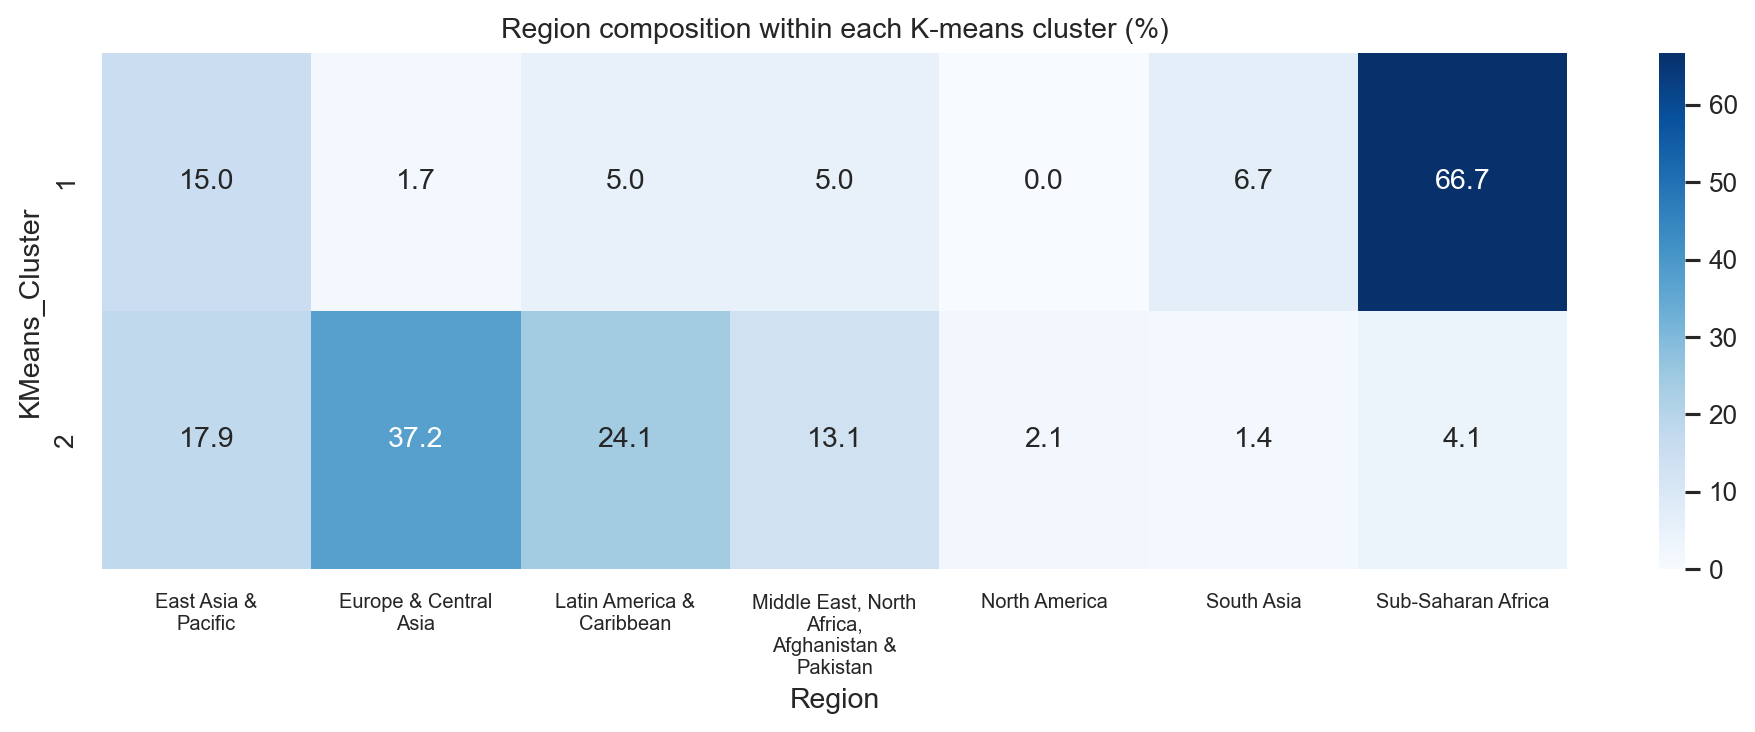

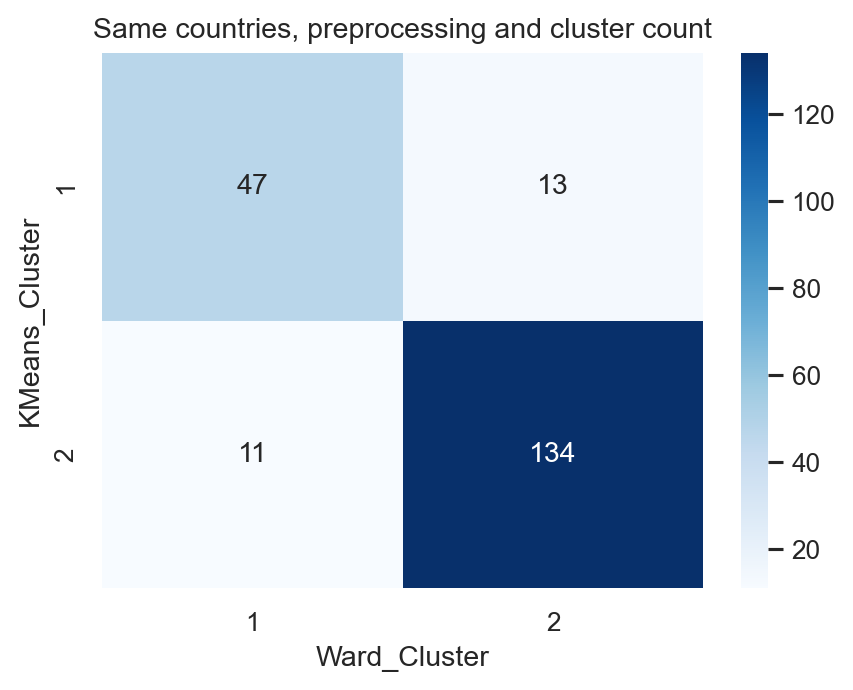

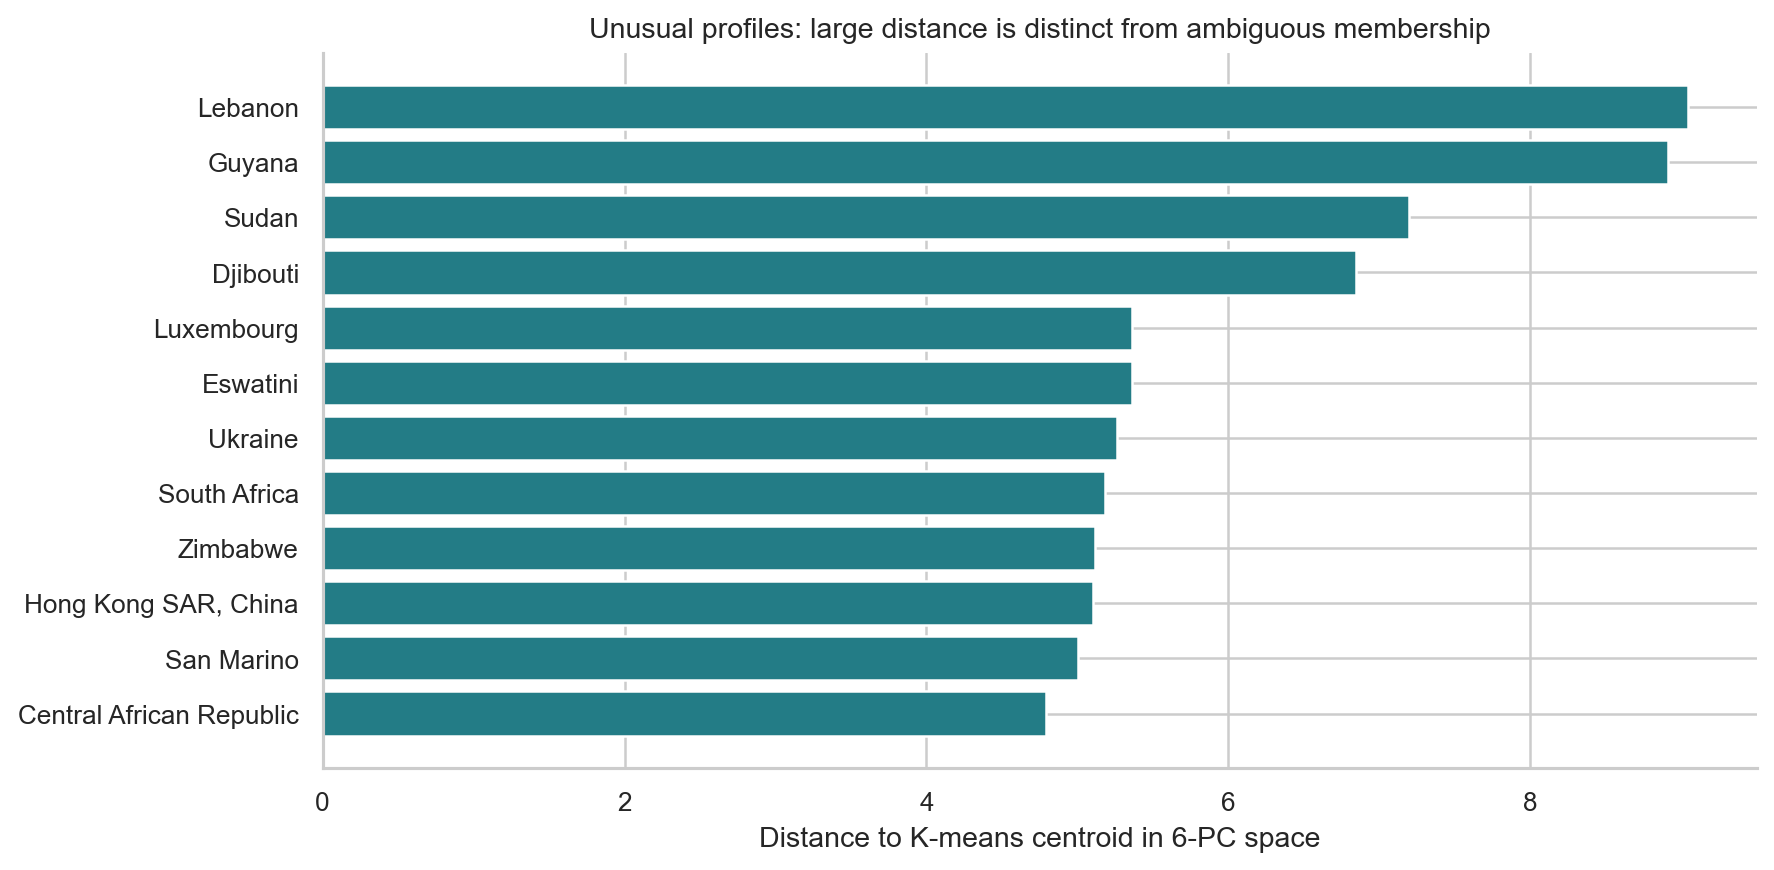

,Country Name,KMeans_Cluster,Ward_Cluster,Distance_to_Centroid,Within_Cluster_Distance_Percentile,Silhouette,Imputed_Indicators
103,Lebanon,2,1,9.047595,100.000000,0.025295,0
78,Guyana,2,2,8.910230,99.310345,0.052316,3
174,Sudan,1,1,7.197514,100.000000,0.085387,2
51,Djibouti,2,1,6.843178,98.620690,0.035097,1
108,Luxembourg,2,2,5.362871,97.931034,0.306676,0
59,Eswatini,1,1,5.361885,98.333333,0.048707,2
192,Ukraine,2,2,5.261158,97.241379,0.086125,2
168,South Africa,2,1,5.179590,96.551724,0.073292,0
204,Zimbabwe,1,1,5.117517,96.666667,0.176678,1
81,"Hong Kong SAR, China",2,2,5.102795,95.862069,0.308272,0


,Country Name,KMeans_Cluster,Ward_Cluster,Silhouette,Imputed_Indicators
57,Equatorial Guinea,1,2,-0.008582,1
184,Tonga,1,2,-0.056911,0


In [8]:
with threadpool_limits(limits=1):
    project.interpretation(state)
display(state['method_comparison'].round(4))
display(state['cross'])
show_figures('14_cluster_profiles', '15_clusters_vs_income', '16_clusters_vs_regions',
             '17_algorithm_cross_table', '18_unusual_countries')
display(state['assigned'].sort_values('Distance_to_Centroid', ascending=False)
        [['Country Name', 'KMeans_Cluster', 'Ward_Cluster', 'Distance_to_Centroid',
          'Within_Cluster_Distance_Percentile', 'Silhouette', 'Imputed_Indicators']].head(12))
display(state['assigned'].loc[state['assigned'].Silhouette < 0,
        ['Country Name', 'KMeans_Cluster', 'Ward_Cluster', 'Silhouette', 'Imputed_Indicators']])


### Interpreting the country cases

Lebanon's source measurements combine very high inflation and low capital formation. Guyana has exceptionally high GDP growth. Sudan has high inflation, while Luxembourg has high trade relative to GDP. These measurements explain why their profiles deserve inspection; causal stories would require separate evidence. The exported country-driver table identifies the largest observed deviations from the assigned cluster's standardized profile.

Imputed values must not be presented as measured facts. For example, Guyana has several missing indicators and Monaco has five. Use the individual flags and original-unit counts when drawing conclusions.


### 5.1 External agreement: 2022 indicators versus 2026 metadata

These comparisons use **2022 WDI measurements and the World Bank country metadata snapshot retrieved on 23 November 2026**. Scores measure agreement with reference labels, not prediction accuracy or recovery of historical 2022 income groups. Both algorithms are compared with both income group and region; all four rows show the sample size. The income and region crosstabs sit alongside the metrics.


In [9]:
display(state['external_agreement'].round(4))
for method in ['kmeans', 'ward']:
    for label in ['IncomeGroup', 'Region']:
        print(method, label, 'counts')
        display(pd.read_csv(ROOT / 'outputs/tables' / f'16_{method}_{label}_counts.csv', index_col=0))


,algorithm,reference_label,n,ARI,NMI,indicator_year,metadata_snapshot_date
0,K-means,IncomeGroup,205,0.3190,0.4057,2022,2026-11-23
1,K-means,Region,205,0.1725,0.2452,2022,2026-11-23
2,Ward,IncomeGroup,205,0.2601,0.3361,2022,2026-11-23
3,Ward,Region,205,0.1639,0.2477,2022,2026-11-23


kmeans IncomeGroup counts


,Low income,Lower middle income,Upper middle income,High income
KMeans_Cluster,,,,
1,21,34,5,0
2,0,13,54,78


kmeans Region counts


,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
KMeans_Cluster,,,,,,,
1,9,1,3,3,0,4,40
2,26,54,35,19,3,2,6


ward IncomeGroup counts


,Low income,Lower middle income,Upper middle income,High income
Ward_Cluster,,,,
1,21,28,9,0
2,0,19,50,78


ward Region counts


,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
Ward_Cluster,,,,,,,
1,5,0,5,9,0,0,39
2,30,55,33,13,3,6,7


### 5.2 Imputation-aware cluster profiles

Each row combines cluster size, original-unit observed-only median, observed count, imputed count and imputed percentage. Secondary enrollment has 68 imputed values among the retained 205 economies. Medians for imputation are fitted globally on transformed numerical inputs (after ln GDP); they are not fitted within income, region or lending categories. A cluster profile dominated by imputed values needs cautious interpretation.


In [10]:
display(state['cluster_measurement_coverage'].round(3))


,algorithm,cluster,cluster_size,feature,observed_count,imputed_count,imputed_percent,observed_only_median
0,K-means,1,60,GDP_PC,60,0,0.000,1490.500
1,K-means,1,60,GDP_Growth,60,0,0.000,4.141
2,K-means,1,60,Inflation,55,5,8.333,9.090
3,K-means,1,60,Unemployment,59,1,1.667,4.540
4,K-means,1,60,Trade,54,6,10.000,61.260
5,K-means,1,60,Capital_Formation,52,8,13.333,22.151
6,K-means,1,60,Life_Expectancy,60,0,0.000,65.260
7,K-means,1,60,Urban_Population,60,0,0.000,38.221
8,K-means,1,60,Internet_Users,54,6,10.000,35.723
9,K-means,1,60,Electricity_Access,60,0,0.000,58.850


### 5.3 Two of the 24 method disagreements

Choose one economy from each direction of disagreement using the alphabetically ordered country table. Inspect every measured indicator and its imputation flag rather than attributing a difference to an invented cause. A disagreement means two algorithms choose different partitions; negative K-means silhouette means proximity to the alternative K-means cluster in the same geometry. A country can have positive within-model silhouette and still receive a different Ward assignment.

Bangladesh is assigned to K-means group 1 and Ward group 2. Its measured GDP per capita is about US$2,716 and Internet usage 41.6%, alongside life expectancy of 74.3 years and electricity access of 99.4%: a mixed profile across income/connectivity and health/electricity. All 11 indicators are observed. Botswana shows the reverse assignment (K-means 2, Ward 1): GDP per capita about US$8,329 and urbanization 66.6%, alongside electricity access 75.9%, Internet usage 57.9% and life expectancy 68.7 years. Its secondary-enrollment value is imputed and should not be presented as a measured explanation. These mixed profiles are consistent with different algorithmic boundaries; the measurements alone do not prove the causal reason for the difference. Both have positive K-means silhouettes (0.152 and 0.089), illustrating that cross-algorithm disagreement does not require negative within-model silhouette.


In [11]:
cases = state['disagreement_cases']
display(cases.round(3))
for country, measurements in cases.groupby('Country Name', sort=False):
    first = measurements.iloc[0]
    print(f"{country}: K-means {int(first.KMeans_Cluster)}, Ward {int(first.Ward_Cluster)}, K-means silhouette {first.KMeans_silhouette:.3f}; {int(measurements.imputed.sum())} imputed indicators.")
    print(measurements.loc[measurements.feature.isin(['GDP_PC','Life_Expectancy','Internet_Users','Urban_Population']), ['feature','observed_value','imputed']].to_string(index=False))


,Country Code,Country Name,KMeans_Cluster,Ward_Cluster,KMeans_silhouette,feature,observed_value,imputed
0,BGD,Bangladesh,1,2,0.152,GDP_PC,2716.486,False
1,BGD,Bangladesh,1,2,0.152,GDP_Growth,7.100,False
2,BGD,Bangladesh,1,2,0.152,Inflation,7.697,False
3,BGD,Bangladesh,1,2,0.152,Unemployment,4.593,False
4,BGD,Bangladesh,1,2,0.152,Trade,33.780,False
5,BGD,Bangladesh,1,2,0.152,Capital_Formation,32.047,False
6,BGD,Bangladesh,1,2,0.152,Life_Expectancy,74.265,False
7,BGD,Bangladesh,1,2,0.152,Urban_Population,31.674,False
8,BGD,Bangladesh,1,2,0.152,Internet_Users,41.617,False
9,BGD,Bangladesh,1,2,0.152,Electricity_Access,99.400,False


Bangladesh: K-means 1, Ward 2, K-means silhouette 0.152; 0 imputed indicators.
         feature  observed_value  imputed
          GDP_PC     2716.485928    False
 Life_Expectancy       74.265000    False
Urban_Population       31.673735    False
  Internet_Users       41.616501    False
Botswana: K-means 2, Ward 1, K-means silhouette 0.089; 1 imputed indicators.
         feature  observed_value  imputed
          GDP_PC     8328.709057    False
 Life_Expectancy       68.749000    False
Urban_Population       66.588979    False
  Internet_Users       57.900000    False


## 6. Robustness and comparison with the original baseline

The diagnostics assess raw versus logged GDP, full standardized features, 90%-variance PCA, a stricter missingness rule, complete cases, a three-group cut, removal of GDP, and exclusion of the source-quality flag. They reuse the same permitted clustering algorithms. The GDP-removal experiment is only a diagnostic; the primary model keeps all 11 required indicators. Each diagnostic refits its imputer, scaler and PCA.

Ten random seeds assess initialization sensitivity with 50 starts per seed. This does not establish stability to every source of sampling or modeling uncertainty. Comparisons with the primary partition use common economies only.

**Silhouettes in different feature spaces or samples are not directly ranked as universal model quality.** Transformations are justified by distributional properties and interpretation, rather than by maximizing agreement with known income groups or between algorithms.

### 6.1 Each algorithm against its own main fit

The robustness table matches economies by country code. It reports each method's ARI against its own main fit, the number of common economies, and the ARI between methods. Switching from logged to raw GDP barely changes K-means (0.980) but changes Ward substantially (0.073). This directly measures each algorithm's sensitivity; between-method ARI is a different comparison.

### 6.2 Complete-case sample versus preprocessing

Keep the same 110 complete-case economies and k=2. A uses their labels from the full main fit; B refits clustering on those economies' original main-fit PC coordinates; C refits imputation/scaling/PCA and clustering on those same economies. A-to-B isolates sample restriction in the same coordinates; B-to-C additionally changes preprocessing (including the PCA dimension selected by the same variance rule). Both algorithms have lower A-to-B agreement than B-to-C agreement here: the sample restriction is the larger change by this comparison. ARI differences are not additive causal contributions. Country-keyed A/B/C labels are exported.

### 6.3 CAF: drop the economy versus mask only its flagged field

The primary WDI value is unchanged. One diagnostic drops CAF (204 economies), while another keeps all 205 and marks only CAF life expectancy missing before refitting the same global median-imputer procedure, scaler and PCA. The latter has 198 imputed cells instead of 197. Compare each method on common countries. Masking and dropping are different changes to the dataset and the fitted geometry; neither invents a corrected value. Ward responds more to masking (ARI about 0.618) than to dropping (about 0.960), so the source anomaly deserves an explicit limitation.


In [12]:
with threadpool_limits(limits=1):
    project.robustness(state)
display(state['robustness'].round(4))
display(state['seeds'].round(5))

raw = state['robustness'].loc[state['robustness'].configuration.eq('Raw GDP baseline')].iloc[0]
print(f"Raw vs logged GDP: K-means own-baseline ARI {raw.KMeans_ARI_vs_main:.3f}; Ward own-baseline ARI {raw.Ward_ARI_vs_main:.3f}.")
display(state['complete_case_decomposition'].round(4))
display(state['robustness'].loc[state['robustness'].configuration.isin(['Source-quality flag excluded', 'CAF life expectancy masked only'])].round(4))


ROBUSTNESS: each algorithm is compared with its own main partition, joined by country code.
                  configuration   n  n_common  dimensions  k  silhouette_in_own_space  KMeans_ARI_vs_main  Ward_ARI_vs_main  ARI_vs_main_common_countries  ARI_KMeans_vs_Ward  imputed_cells KMeans_sizes Ward_sizes
         Main: log GDP, PCA 80% 205       205           6  2                   0.3572              1.0000            1.0000                        1.0000              0.5712            197       60;145     58;147
               Raw GDP baseline 205       205           6  2                   0.3235              0.9799            0.0725                        0.9799              0.0801            197       61;144     130;75
     Log GDP, no PCA truncation 205       205          11  2                   0.3091              1.0000            0.7191                        1.0000              0.7547            197       60;145     61;144
               Log GDP, PCA 90% 205       205           

Complete-case decomposition: fixed k, identical 110-country sample in A/B/C; ARI effects are not additive.
algorithm   n  k  A_to_B_ARI_sample_restriction  B_to_C_ARI_preprocessing_refit  A_to_C_ARI_total  main_PC_dimensions  refitted_PC_dimensions
   KMeans 110  2                         0.4051                          0.6301            0.6997                   6                       5
     Ward 110  2                         0.0392                          0.7595            0.0489                   6                       5


,configuration,n,n_common,dimensions,k,silhouette_in_own_space,KMeans_ARI_vs_main,Ward_ARI_vs_main,ARI_vs_main_common_countries,ARI_KMeans_vs_Ward,imputed_cells,KMeans_sizes,Ward_sizes
0,"Main: log GDP, PCA 80%",205,205,6,2,0.3572,1.0000,1.0000,1.0000,0.5712,197,60;145,58;147
1,Raw GDP baseline,205,205,6,2,0.3235,0.9799,0.0725,0.9799,0.0801,197,61;144,130;75
2,"Log GDP, no PCA truncation",205,205,11,2,0.3091,1.0000,0.7191,1.0000,0.7547,197,60;145,61;144
3,"Log GDP, PCA 90%",205,205,7,2,0.3361,1.0000,0.7745,1.0000,0.5476,197,60;145,70;135
4,"Log GDP, at most 3 missing",190,190,6,2,0.3458,0.9786,0.4576,0.9786,0.4306,130,60;130,30;160
5,"Log GDP, complete cases",110,110,5,2,0.3583,0.6997,0.0489,0.6997,0.1837,0,28;82,59;51
6,"Log GDP, PCA 80%, k=3",205,205,6,3,0.2140,0.3106,0.9258,0.3106,0.2784,197,40;94;71,38;20;147
7,GDP omitted diagnostic,205,205,6,2,0.3409,0.9799,0.2592,0.9799,0.2902,196,59;146,106;99
8,Source-quality flag excluded,204,204,6,2,0.3572,0.9798,0.9596,0.9798,0.5860,196,60;144,59;145
9,CAF life expectancy masked only,205,205,6,2,0.3567,0.9799,0.6184,0.9799,0.5407,198,61;144,38;167


,seed,ARI_vs_main,silhouette
0,0,1.0,0.35718
1,1,1.0,0.35718
2,2,1.0,0.35718
3,3,1.0,0.35718
4,4,1.0,0.35718
5,5,1.0,0.35718
6,6,1.0,0.35718
7,7,1.0,0.35718
8,8,1.0,0.35718
9,9,1.0,0.35718


Raw vs logged GDP: K-means own-baseline ARI 0.980; Ward own-baseline ARI 0.073.


,algorithm,n,k,A_to_B_ARI_sample_restriction,B_to_C_ARI_preprocessing_refit,A_to_C_ARI_total,main_PC_dimensions,refitted_PC_dimensions
0,KMeans,110,2,0.4051,0.6301,0.6997,6,5
1,Ward,110,2,0.0392,0.7595,0.0489,6,5


,configuration,n,n_common,dimensions,k,silhouette_in_own_space,KMeans_ARI_vs_main,Ward_ARI_vs_main,ARI_vs_main_common_countries,ARI_KMeans_vs_Ward,imputed_cells,KMeans_sizes,Ward_sizes
8,Source-quality flag excluded,204,204,6,2,0.3572,0.9798,0.9596,0.9798,0.5860,196,60;144,59;145
9,CAF life expectancy masked only,205,205,6,2,0.3567,0.9799,0.6184,0.9799,0.5407,198,61;144,38;167


## 7. Structural validation and exported results

The run verifies finite inputs, scaling, PCA retention, country-row alignment, cluster counts and held-out metadata. The additional test script also changes all metadata labels and checks that neither preprocessing nor clustering changes. It verifies both the main result and the original teammate baseline against the frozen snapshot.

Run `python tests/check_results.py` after the analysis. The analysis generates figures and tables under `outputs/` and country assignments under `data/processed/`.

The executable test joins expected and exported assignments by country code and compares both model labels. It also creates a temporary corrupted export with two codes swapped and runs the test script against it, requiring rejection. Row reordering alone must pass. The original audited 205 assignments are retained in reference/benchmark_v1 and checked against the main result.


In [13]:
summary = project.validate_and_save(state)
display(Markdown(f"**Completed:** {summary['counts']['retained']} economies; "
                 f"{summary['n_components']} PCs retain {summary['retained_variance']:.2%} of variance; "
                 f"selected k={summary['selected_k']}."))
display(Markdown(f"K-means silhouette = {summary['kmeans_silhouette']:.3f}; "
                 f"Ward silhouette = {summary['ward_silhouette']:.3f}; "
                 f"between-method ARI = {summary['ari_between_methods']:.3f}."))


All structural checks passed. Results written to outputs/results.json.
{
  "configuration": {
    "year": 2022,
    "missing_fraction_max": 0.5,
    "log_gdp": true,
    "pca_variance_target": 0.8,
    "k_values": [
      2,
      3,
      4,
      5,
      6,
      7,
      8
    ],
    "random_state": 42,
    "n_init": 50,
    "hierarchical_linkage": "ward",
    "candidate_years": [
      2021,
      2022,
      2023,
      2024
    ],
    "year_min_retained_fraction": 0.9,
    "year_min_complete_fraction": 0.5
  },
  "counts": {
    "wdi_entities": 266,
    "metadata_economies": 217,
    "matched_economies": 217,
    "excluded": 12,
    "retained": 205,
    "complete_cases": 110,
    "coded_aggregates": 44,
    "uncoded_income_aggregates": 5
  },
  "features": [
    "GDP_PC",
    "GDP_Growth",
    "Inflation",
    "Unemployment",
    "Trade",
    "Capital_Formation",
    "Life_Expectancy",
    "Urban_Population",
    "Internet_Users",
    "Electricity_Access",
    "Secondary_Enrollm

**Completed:** 205 economies; 6 PCs retain 84.67% of variance; selected k=2.

K-means silhouette = 0.357; Ward silhouette = 0.340; between-method ARI = 0.571.

### Quantified interpretation of the final groups

The observed median GDP per capita is US$1,491 in group 1 and US$15,565 in group 2. Corresponding median life expectancies are 65.3 and 76.6 years; median Internet usage is 35.7% and 84.9%. These are observed-only medians, with feature-specific counts exported. Group 1 describes lower average development/infrastructure measurements and group 2 higher measurements, while macroeconomic exceptions remain.

All 21 retained economies labelled low income fall in group 1, and all 78 labelled high income fall in group 2. Middle-income economies span both groups: in particular, 13 lower-middle-income economies belong to group 2. These are comparisons with the 2026 metadata snapshot, not historical 2022 classifications.

The GDP-ordered K-means and Ward groupings disagree for 24 of 205 economies. The country list identifies them; the two algorithms produce similar broad structure but do not reproduce an identical partition.

The GDP-omission diagnostic has ARI 0.980 against the primary K-means grouping, indicating that the other ten features reproduce almost the same broad split. Excluding the source-quality flagged economy yields K-means ARI 0.980 on common economies. The field-masking diagnostic and Ward results are reported separately in section 6.3; their differences prevent a blanket claim of robustness to the anomaly. These checks limit the claim that the observed split is solely a raw-income artifact or solely a consequence of that one questionable value; they do not establish a unique natural partition.


## Conclusions and limits

The numerical sample supports a broad socioeconomic split associated with infrastructure, connectivity, health and income. The two groups remain descriptive summaries, with overlapping country profiles and macroeconomic exceptions. The robustness table establishes which assignments persist and which depend on preprocessing, exclusions or cluster count; it does not turn one algorithm into ground truth.

The current-income comparison is temporally different from a historical 2022 classification. Missing data and source anomalies limit country-specific claims. Global median imputation compresses variation, correlated indicators affect the distance geometry, and retaining high-variance PCs can omit substantively interesting differences. Economies are weighted equally, not by population, and the one-year study cannot establish causal effects or development trajectories.

### Sources and method documentation

- WDI: https://datatopics.worldbank.org/world-development-indicators/
- Indicator IDs and retrieval URLs: `data/provenance.json` and `INDICATORS` in `analysis.py`.
- Country metadata: https://api.worldbank.org/v2/country?format=json&per_page=400
- Source-quality point-series check: `DATA_QUALITY.md` and `data/quality_checks/`.
- scikit-learn clustering: https://scikit-learn.org/stable/modules/clustering.html
- PCA: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- The raw-GDP sensitivity analysis reproduces the original teammate PCA baseline.
